# rn222_correction_test

Diagnose whether the AFT correction (Correction 1) should be done per-partition instead of globally.

Loads pre-correction data (`df_cut` state), fits the `exp_bump_model` centerline per partition,
and compares centerlines between partitions and between S1-only vs S1+S2 datasets.

---
## 1. Imports & Setup

In [28]:
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import curve_fit
from datetime import datetime, timezone
import warnings
warnings.filterwarnings('ignore')

def safe_tight(fig=None):
    try: (fig or plt).tight_layout()
    except Exception: pass

def exp_bump_model(x, a, b, c, d, e):
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

def to_ts(date_str):
    return pd.Timestamp(date_str, tz='UTC').timestamp()

print('Setup complete.')

Setup complete.


---
## 2. Partitions & Band Selection

In [29]:
# Updated 4-partition scheme (Q5-driven, Jul 27)
partitions = [
    ('P1: OLD Q5',                    to_ts('2026-05-01'), to_ts('2026-05-11')),
    ('P2: ST707, Q5 removed',          to_ts('2026-05-11'), to_ts('2026-05-26')),
    ('P3: ST707, Q5 Rn cleaned',       to_ts('2026-05-26'), to_ts('2026-06-12')),
    ('P4: FRESH Q5',                   to_ts('2026-06-12'), to_ts('2026-07-02')),
]

RN_UPPER = [8.86e+04, -0.0600, -0.0900, -0.0600, 68000]
RN_LOWER = [7.30e+04, -0.0600, -0.0900, -0.0600, 58000]
AFT_FIT_MIN, AFT_FIT_MAX = 0.12, 0.55
AFT_REF = 0.30

for p in partitions:
    print('  %s' % p[0])

def assign_partition(start_s):
    for name, t0, t1 in partitions:
        if t0 <= start_s < t1: return name
    return None


  P1: Q5 (May 1–11)
  P2: ST707 (May 11–25)
  P3: NO purifier (May 25–Jun5)
  P4: Dist. on (Jun 5–20)
  P5: LXe lvl Δ (Jun 20–Jul2)


---
## 3. Load Pre-Correction Data

In [30]:
# S1-only
df_s1only = pd.read_pickle(
    '/project2/lgrandi/jietang/sr3_commissioning/sr3_rn222_s1only_pre_corr.pkl'
)
df_s1only['partition'] = df_s1only['time'].apply(
    lambda t: assign_partition(t / 1e9)
)
print('S1-only: %d events' % len(df_s1only))
print(df_s1only['partition'].value_counts().sort_index())

# S1+S2
df_s1s2 = pd.read_pickle(
    '/project2/lgrandi/jietang/sr3_commissioning/sr3_rn222_s1s2_pre_corr.pkl'
)
df_s1s2['partition'] = df_s1s2['time'].apply(
    lambda t: assign_partition(t / 1e9)
)
print('\nS1+S2: %d events' % len(df_s1s2))
print(df_s1s2['partition'].value_counts().sort_index())

S1-only: 2264866 events
partition
P1: Q5 (May 1–11)                 87214
P2: ST707 (May 11–25)            593050
P3: NO purifier (May 25–Jun5)    709711
P5: LXe lvl Δ (Jun 20–Jul2)      708046
Name: count, dtype: int64

S1+S2: 32780402 events
partition
P1: Q5 (May 1–11)                 1594703
P2: ST707 (May 11–25)             1205692
P3: NO purifier (May 25–Jun5)      943000
P4: Dist. on (Jun 5–20)           1879107
P5: LXe lvl Δ (Jun 20–Jul2)      23713683
Name: count, dtype: int64


---
## 4. Fit Centerline per Partition

In [31]:
# Fit exp_bump_model per partition (TWO-STEP refinement)
# Step 1: initial fit using manual RN_UPPER / RN_LOWER boundaries
# Step 2: refine — vertical cut (±1σ) in area_aft_corrected, re-fit

def fit_centerline(df, aft_min=0.12, aft_max=0.55, n_bins=50):
    """Two-step per-partition centerline fit.
    Returns dict: pname -> (p_opt, d_fit) where p_opt is refined params."""
    results = {}
    for pname, t0, t1 in partitions:
        d = df[df["partition"] == pname].copy()
        if len(d) < 100:
            print("  %s: too few events (%d), skipping" % (pname, len(d)))
            results[pname] = None
            continue

        d_fit = d[(d["area_fraction_top"] >= aft_min) &
                  (d["area_fraction_top"] <= aft_max)].copy()

        # ── Step 1: manual boundary selection ──
        d_fit["in_band"] = (
            (d_fit["area"] < exp_bump_model(d_fit["area_fraction_top"], *RN_UPPER)) &
            (d_fit["area"] > exp_bump_model(d_fit["area_fraction_top"], *RN_LOWER))
        )

        edges = np.linspace(aft_min, aft_max, n_bins + 1)
        d_fit["aft_bin"] = pd.cut(d_fit["area_fraction_top"], bins=edges)

        medians_init = d_fit[d_fit["in_band"]].groupby("aft_bin", observed=True)["area"].median()
        aft_c = medians_init.index.map(lambda iv: iv.mid).astype(float).values
        m_vals = medians_init.values
        good = ~np.isnan(m_vals)

        if good.sum() < 5:
            print("  %s: insufficient bins (%d), skipping" % (pname, good.sum()))
            results[pname] = None
            continue

        p0 = [3.70e4, -8.97e-2, -0.1, -0.05, 35e3]
        try:
            p_init, _ = curve_fit(exp_bump_model, aft_c[good], m_vals[good], p0=p0,
                                  bounds=([0, -np.inf, -np.inf, -np.inf, 0],
                                          [np.inf, 0, 0, 0, np.inf]), maxfev=10000)
        except Exception as e:
            print("  %s: initial fit FAILED (%s)" % (pname, e))
            results[pname] = None
            continue

        # ── Step 2: refine — vertical cut (±1σ) in corrected space ──
        aft_arr = d_fit["area_fraction_top"].values
        area_arr = d_fit["area"].values
        denom = np.maximum(exp_bump_model(aft_arr, *p_init), 1e3)
        area_corr = area_arr * exp_bump_model(AFT_REF, *p_init) / denom

        mask_band = d_fit["in_band"].values
        mu_rn = np.mean(area_corr[mask_band])
        sig_rn = np.std(area_corr[mask_band])

        d_fit["in_band_refined"] = abs(area_corr - mu_rn) < sig_rn

        medians_ref = d_fit[d_fit["in_band_refined"]].groupby("aft_bin", observed=True)["area"].median()
        aft_c2 = medians_ref.index.map(lambda iv: iv.mid).astype(float).values
        m_vals2 = medians_ref.values
        good2 = ~np.isnan(m_vals2)

        if good2.sum() < 5:
            print("  %s: insufficient refined bins (%d), using initial" % (pname, good2.sum()))
            results[pname] = (p_init, d_fit)
            continue

        try:
            p_opt, _ = curve_fit(exp_bump_model, aft_c2[good2], m_vals2[good2], p0=p_init,
                                  bounds=([0, -np.inf, -np.inf, -np.inf, 0],
                                          [np.inf, 0, 0, 0, np.inf]), maxfev=10000)
        except Exception as e:
            print("  %s: refined fit FAILED (%s), using initial" % (pname, e))
            results[pname] = (p_init, d_fit)
            continue

        area_ref = exp_bump_model(AFT_REF, *p_opt)
        n_inband = d_fit["in_band_refined"].sum()
        print("  %s: a=%.0f e=%.0f  ref_area=%.0f PE  "
              "(%d in-band, \u03bc=%.0f \u03c3=%.0f)"
              % (pname.split(":")[0], p_opt[0], p_opt[4], area_ref,
                 n_inband, mu_rn, sig_rn))
        results[pname] = (p_opt, d_fit)

    return results

# Fit both datasets
print("=== S1-only (two-step) ===")
cent_s1only = fit_centerline(df_s1only)
print()
print("=== S1+S2 (two-step) ===")
cent_s1s2 = fit_centerline(df_s1s2)


=== S1-only (two-step) ===
  P1: a=30874 e=62919  ref_area=69819 PE  (1824 in-band, μ=69783 σ=2724)
  P2: a=17219398 e=63067  ref_area=68895 PE  (5538 in-band, μ=69006 σ=2675)
  P3: a=32915 e=62466  ref_area=69685 PE  (2758 in-band, μ=69856 σ=2661)
  P4: Dist. on (Jun 5–20): too few events (0), skipping
  P5: a=29893320 e=62248  ref_area=67782 PE  (15027 in-band, μ=68053 σ=2409)

=== S1+S2 (two-step) ===
  P1: a=86958 e=65105  ref_area=70522 PE  (8077 in-band, μ=70263 σ=2715)
  P2: a=10284018 e=63428  ref_area=69469 PE  (5525 in-band, μ=69572 σ=2692)
  P3: a=32841 e=62494  ref_area=69359 PE  (677 in-band, μ=69691 σ=2770)
  P4: a=44327 e=62101  ref_area=67642 PE  (586 in-band, μ=67755 σ=2363)
  P5: a=651852 e=61636  ref_area=67172 PE  (20835 in-band, μ=67399 σ=2286)


---
## 5. S1-only: Per-Partition Centerlines

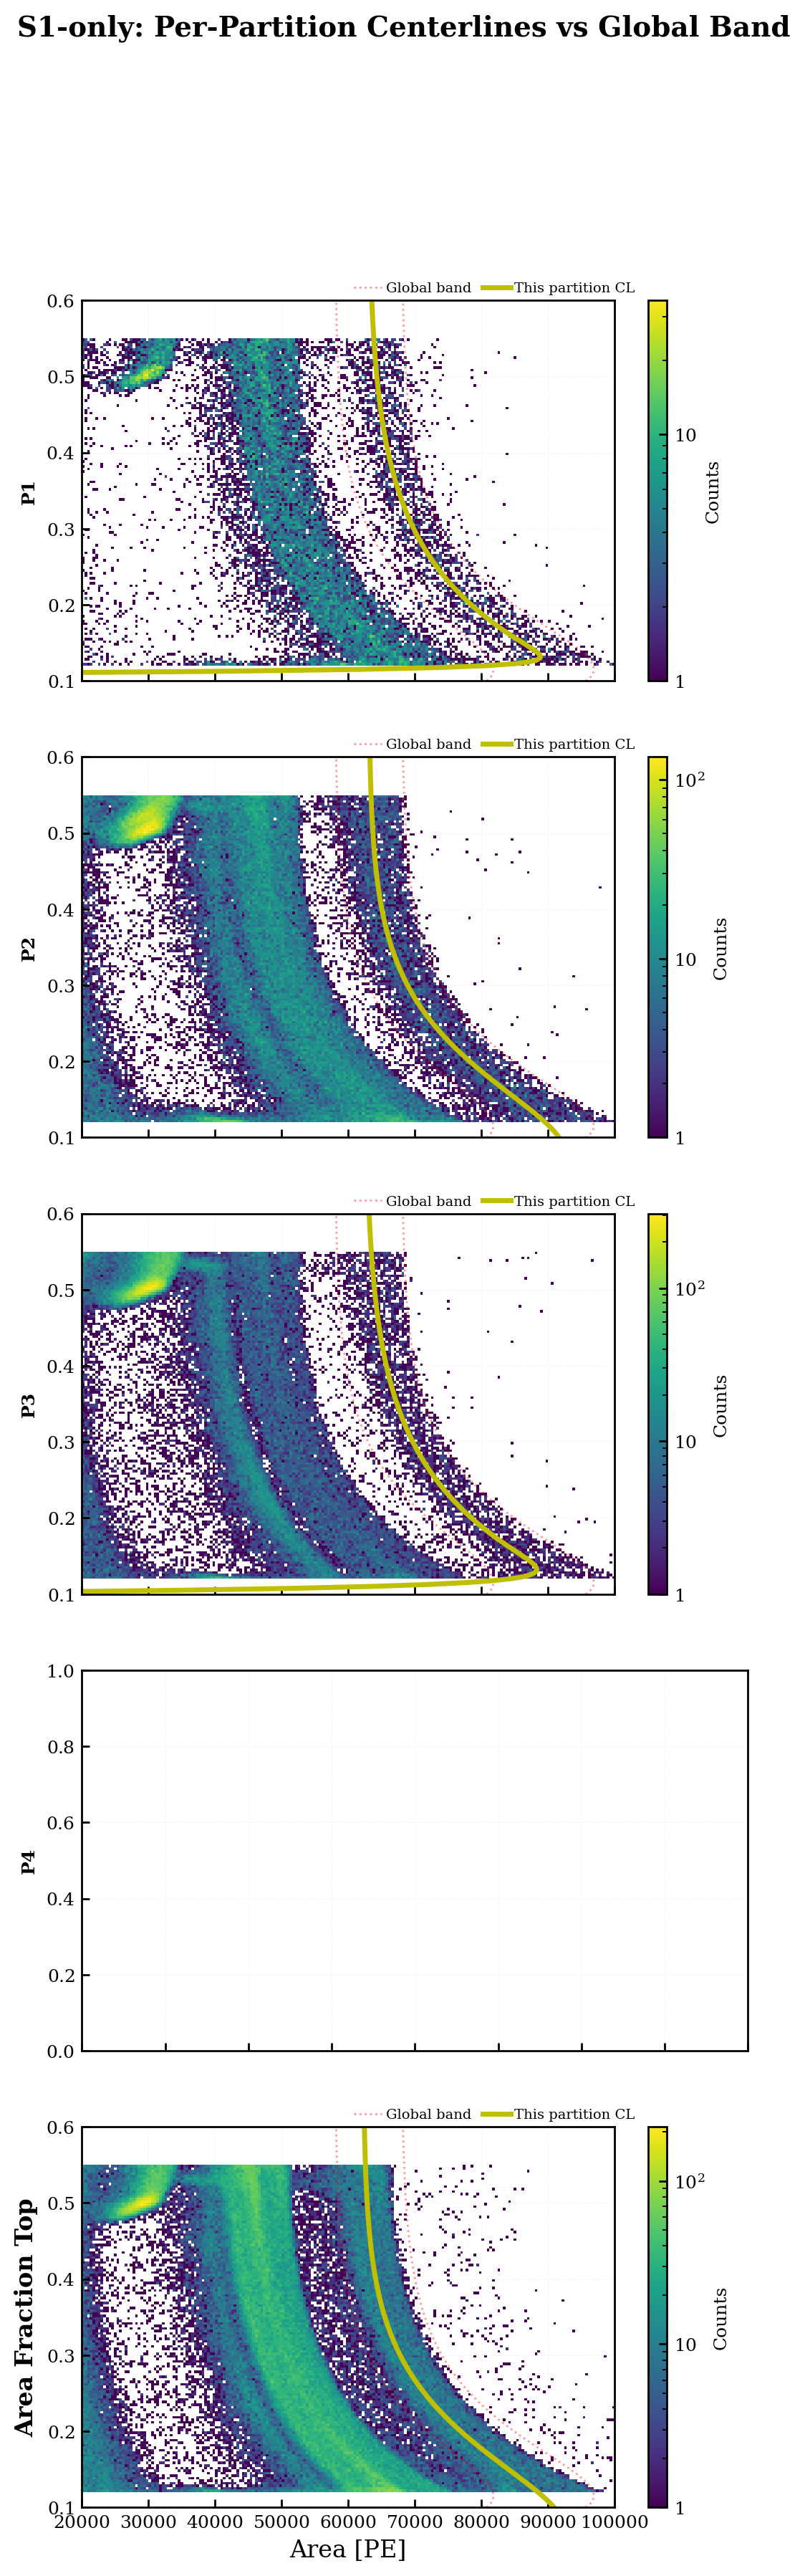

In [32]:
# S1-only: per-partition 2D hist + band bounds + fitted centerline
n_p = len(partitions)
fig, axes = plt.subplots(n_p, 1, figsize=(6, 4 * n_p), sharex=True)
if n_p == 1: axes = [axes]
aft_fine = np.linspace(0.10, 0.60, 200)

for ax, (pname, t0, t1) in zip(axes, partitions):
    res = cent_s1only.get(pname)
    if res:
        p_opt, d_fit = res
        h = ax.hist2d(d_fit['area'], d_fit['area_fraction_top'],
                      bins=[200, 150], range=[[20e3, 100e3], [0.1, 0.6]],
                      cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
        plt.colorbar(h[3], ax=ax, label='Counts')
        # Global band bounds
        ax.plot(exp_bump_model(aft_fine, *RN_UPPER), aft_fine, 'r:', lw=1, alpha=0.4, label='Global band')
        ax.plot(exp_bump_model(aft_fine, *RN_LOWER), aft_fine, 'r:', lw=1, alpha=0.4)
        # Per-partition centerline
        ax.plot(exp_bump_model(aft_fine, *p_opt), aft_fine, 'y-', lw=2.5, label='This partition CL')
    ax.set_ylabel(pname.split(':')[0].replace('(', '\n('), fontsize=9, fontweight='bold')
    ax.legend(fontsize=7, loc='lower left')
    ax.grid(True, alpha=0.15)

axes[-1].set_xlabel('Area [PE]', fontsize=12)
axes[-1].set_ylabel('Area Fraction Top', fontsize=12)
fig.suptitle('S1-only: Per-Partition Centerlines vs Global Band', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()

---
## 6. S1+S2: Per-Partition Centerlines

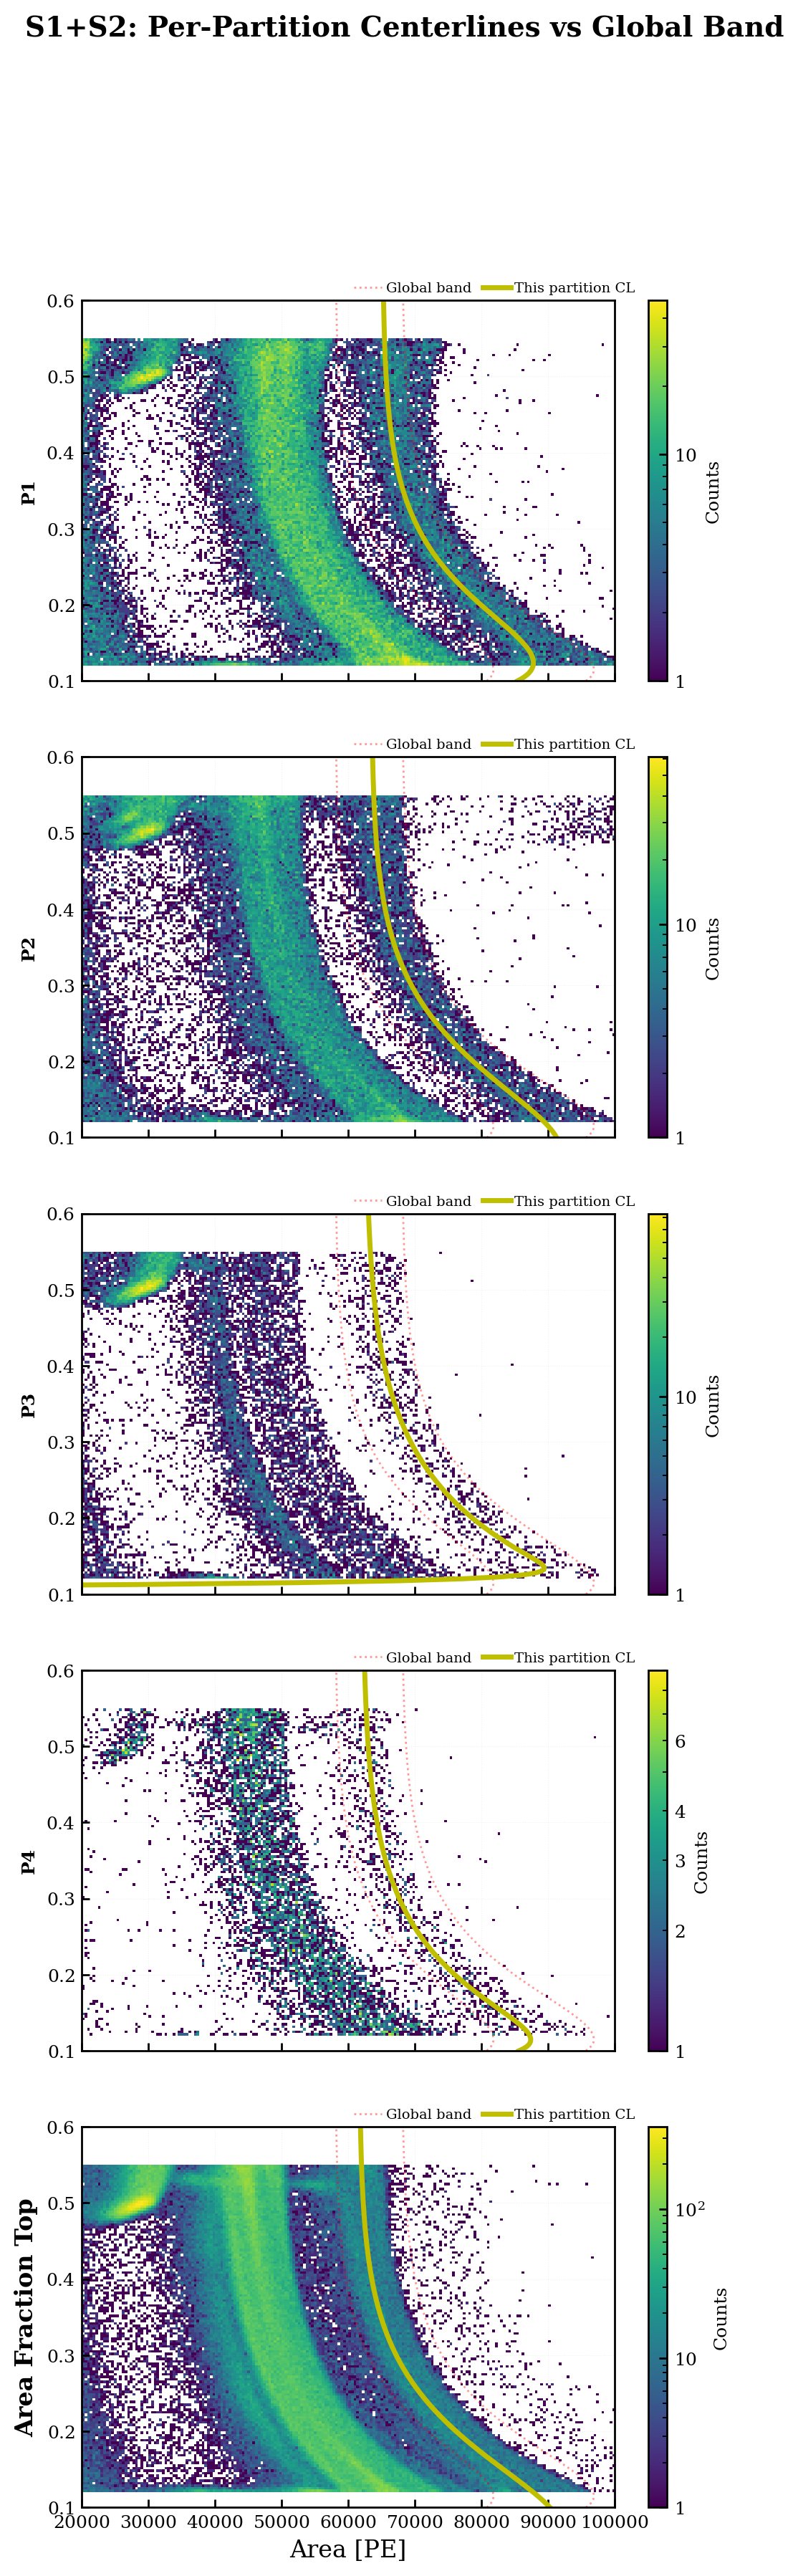

In [33]:
# S1+S2: per-partition 2D hist + band bounds + fitted centerline
fig, axes = plt.subplots(n_p, 1, figsize=(6, 4 * n_p), sharex=True)
if n_p == 1: axes = [axes]

for ax, (pname, t0, t1) in zip(axes, partitions):
    res = cent_s1s2.get(pname)
    if res:
        p_opt, d_fit = res
        h = ax.hist2d(d_fit['area'], d_fit['area_fraction_top'],
                      bins=[200, 150], range=[[20e3, 100e3], [0.1, 0.6]],
                      cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.plot(exp_bump_model(aft_fine, *RN_UPPER), aft_fine, 'r:', lw=1, alpha=0.4, label='Global band')
        ax.plot(exp_bump_model(aft_fine, *RN_LOWER), aft_fine, 'r:', lw=1, alpha=0.4)
        ax.plot(exp_bump_model(aft_fine, *p_opt), aft_fine, 'y-', lw=2.5, label='This partition CL')
    ax.set_ylabel(pname.split(':')[0].replace('(', '\n('), fontsize=9, fontweight='bold')
    ax.legend(fontsize=7, loc='lower left')
    ax.grid(True, alpha=0.15)

axes[-1].set_xlabel('Area [PE]', fontsize=12)
axes[-1].set_ylabel('Area Fraction Top', fontsize=12)
fig.suptitle('S1+S2: Per-Partition Centerlines vs Global Band', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()

---
## 7. Combined Comparison

Overlay all centerlines to quantify the offset between partitions.

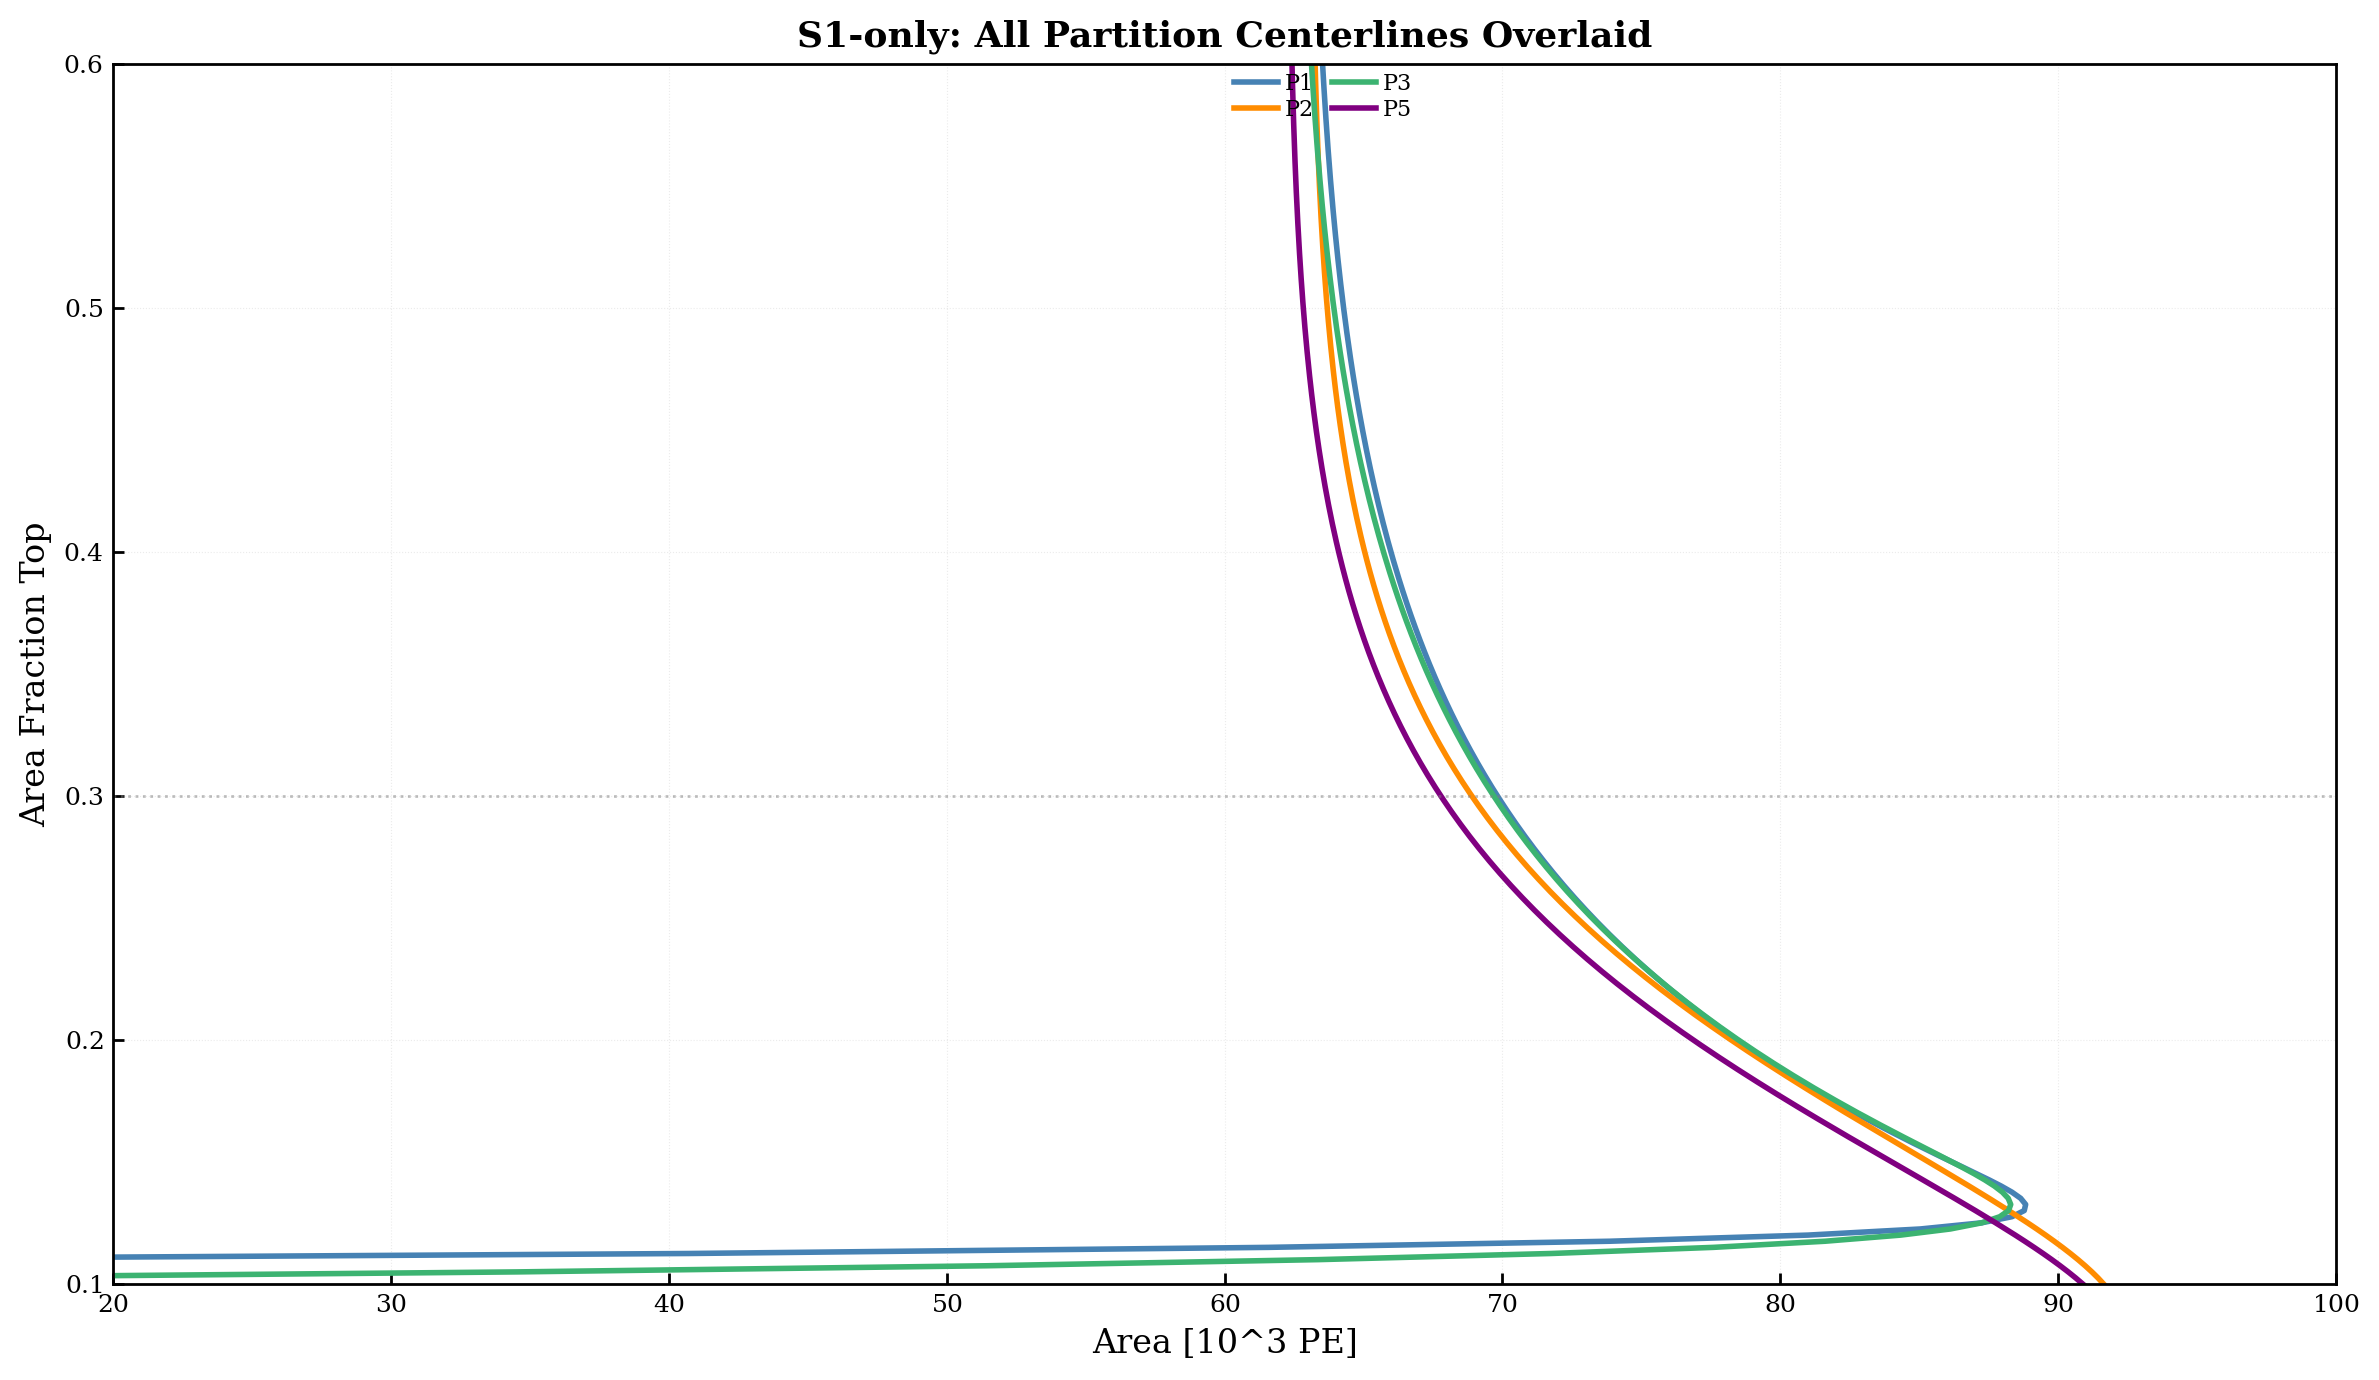

In [34]:
# Overlay all centerlines — S1-only
fig, ax = plt.subplots(figsize=(12, 7))
# 4-partition colors (matches partitions list)
pcolors = ['steelblue', 'darkorange', 'mediumseagreen', 'firebrick']

for idx, (pname, t0, t1) in enumerate(partitions):
    res = cent_s1only.get(pname)
    if res and res[0] is not None:
        p_opt = res[0]
        x = exp_bump_model(aft_fine, *p_opt) / 1e3
        ax.plot(x, aft_fine, color=pcolors[idx], lw=2, label=res[0] if False else pname.split(':')[0])

# Mark reference AFT
ax.axhline(y=AFT_REF, color='gray', ls=':', lw=1, alpha=0.5)

ax.set_xlabel('Area [10^3 PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('S1-only: All Partition Centerlines Overlaid', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.2)
ax.set_xlim(20, 100)
ax.set_ylim(0.10, 0.60)
safe_tight(fig); plt.show()

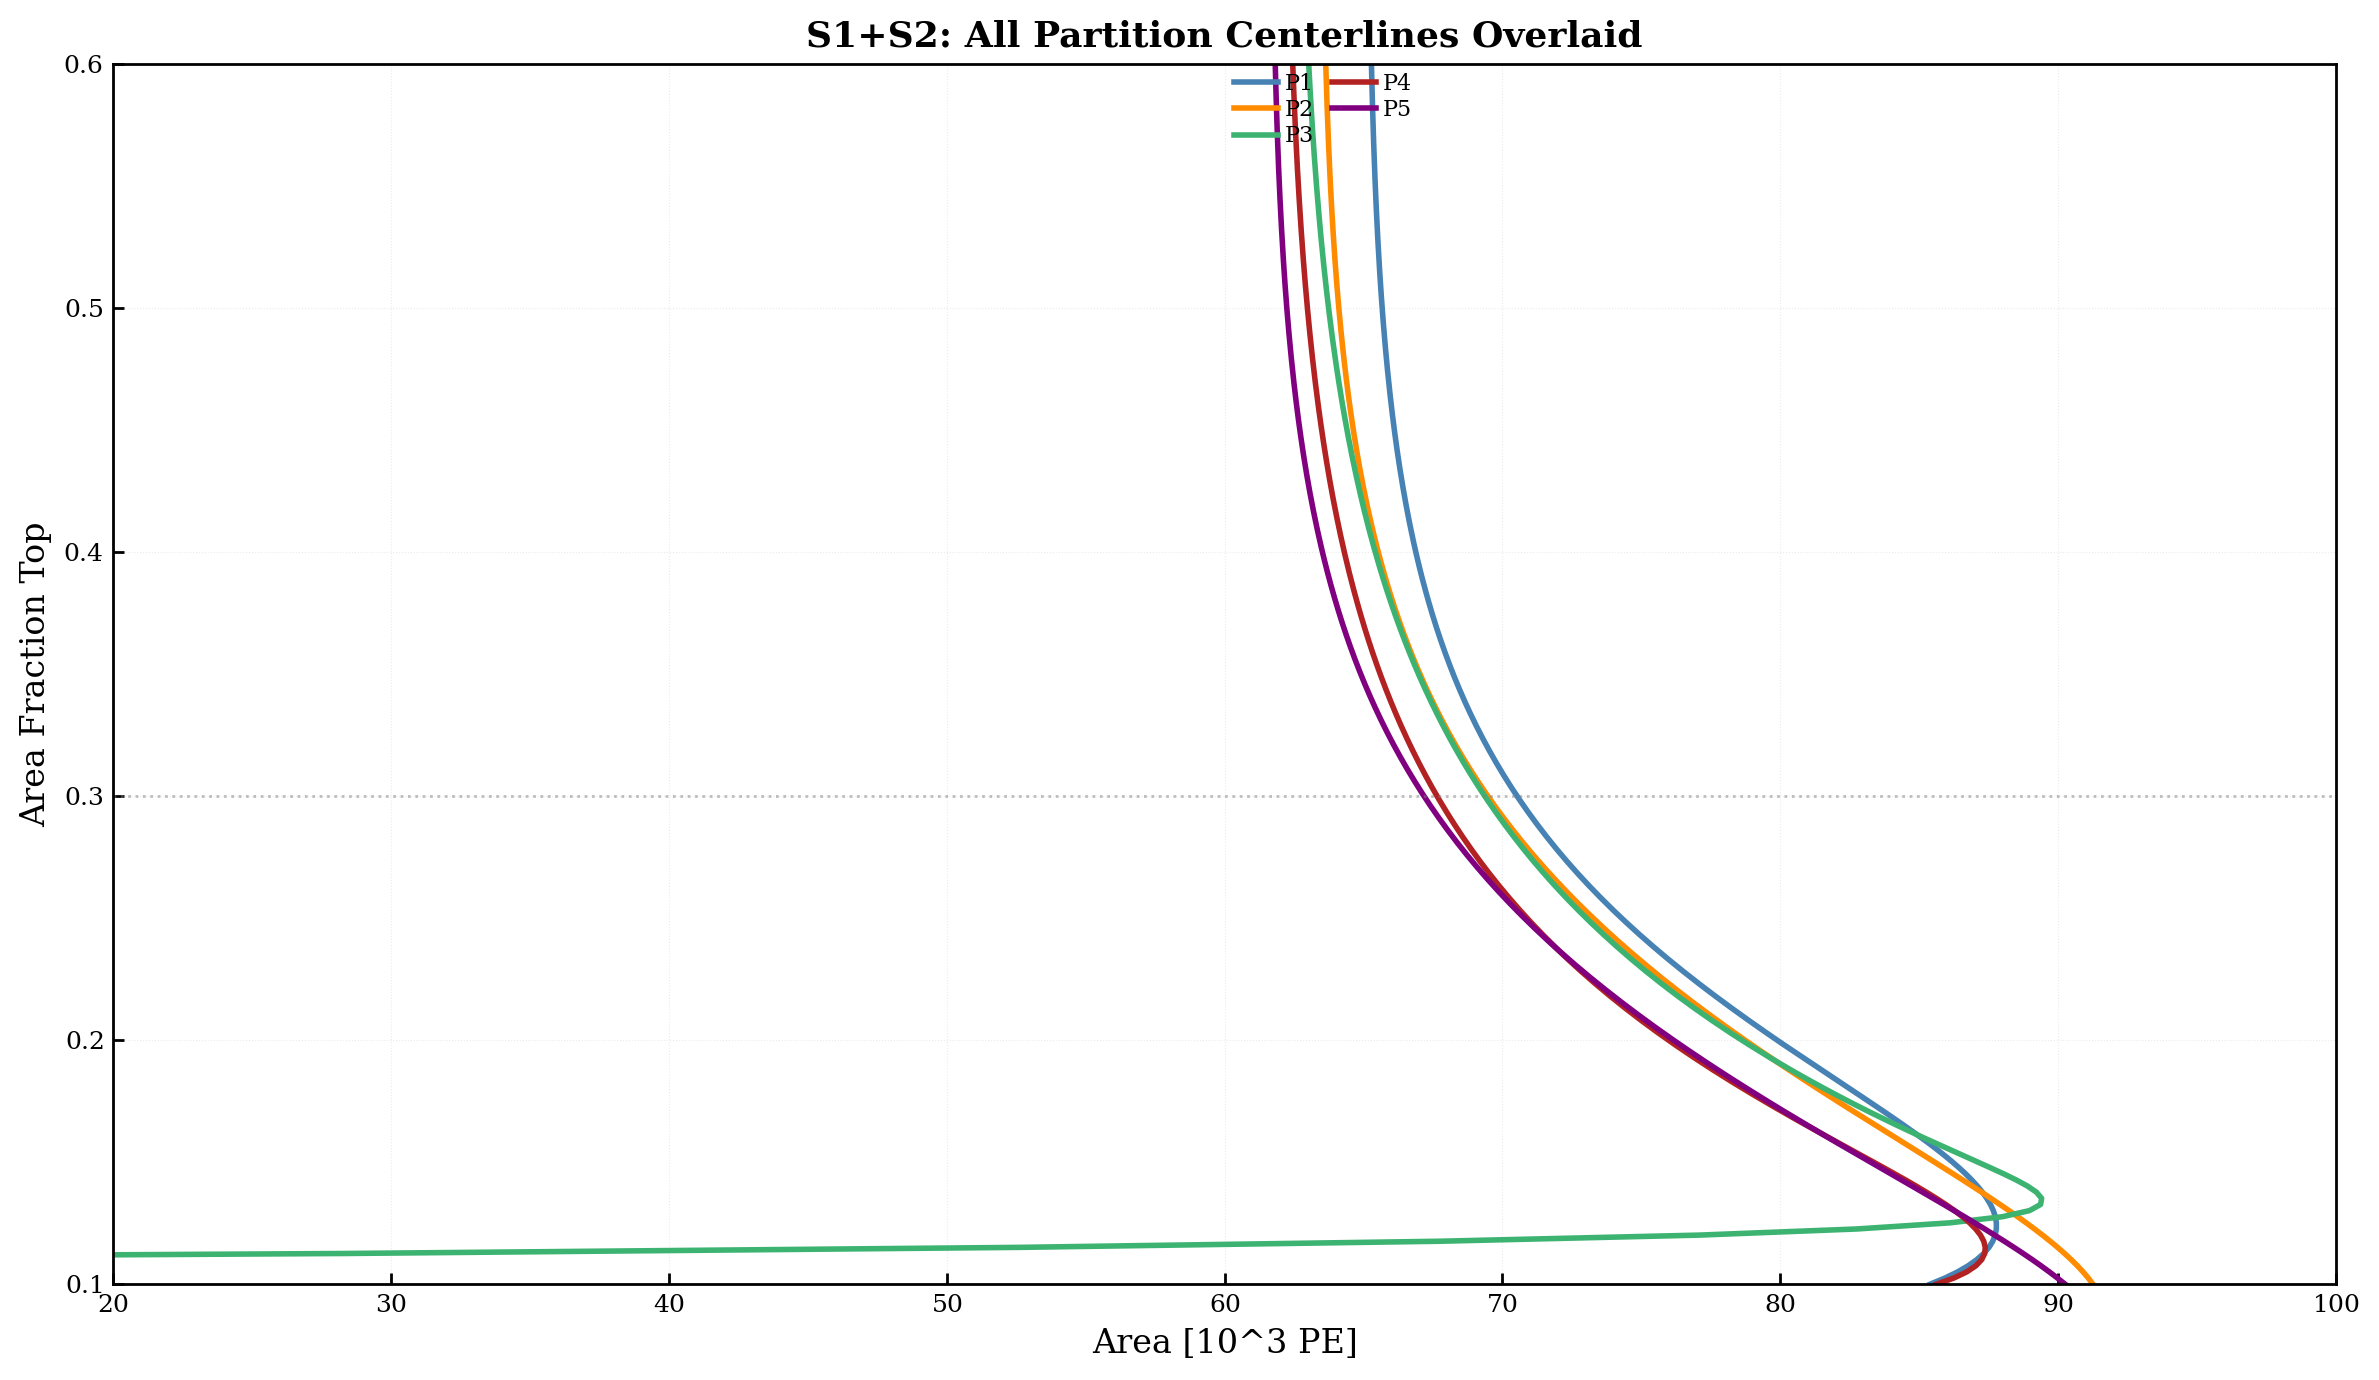

In [35]:
# Overlay all centerlines — S1+S2
pcolors = ["steelblue", "darkorange", "mediumseagreen", "firebrick"]
fig, ax = plt.subplots(figsize=(12, 7))
for idx, (pname, t0, t1) in enumerate(partitions):
    res = cent_s1s2.get(pname)
    if res and res[0] is not None:
        x = exp_bump_model(aft_fine, *res[0]) / 1e3
        ax.plot(x, aft_fine, color=pcolors[idx], lw=2, label=pname.split(':')[0])
ax.axhline(y=AFT_REF, color='gray', ls=':', lw=1, alpha=0.5)
ax.set_xlabel('Area [10^3 PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('S1+S2: All Partition Centerlines Overlaid', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.2)
ax.set_xlim(20, 100); ax.set_ylim(0.10, 0.60)
safe_tight(fig); plt.show()

Ref area at AFT=0.30

Partition                               S1-only       S1+S2
------------------------------------------------------------
P1: Q5 (May 1–11)                      69818 PE    70522 PE
P2: ST707 (May 11–25)                  68895 PE    69468 PE
P3: NO purifier (May 25–Jun5)          69685 PE    69358 PE
P4: Dist. on (Jun 5–20)                     N/A    67641 PE
P5: LXe lvl Δ (Jun 20–Jul2)            67782 PE    67172 PE
------------------------------------------------------------


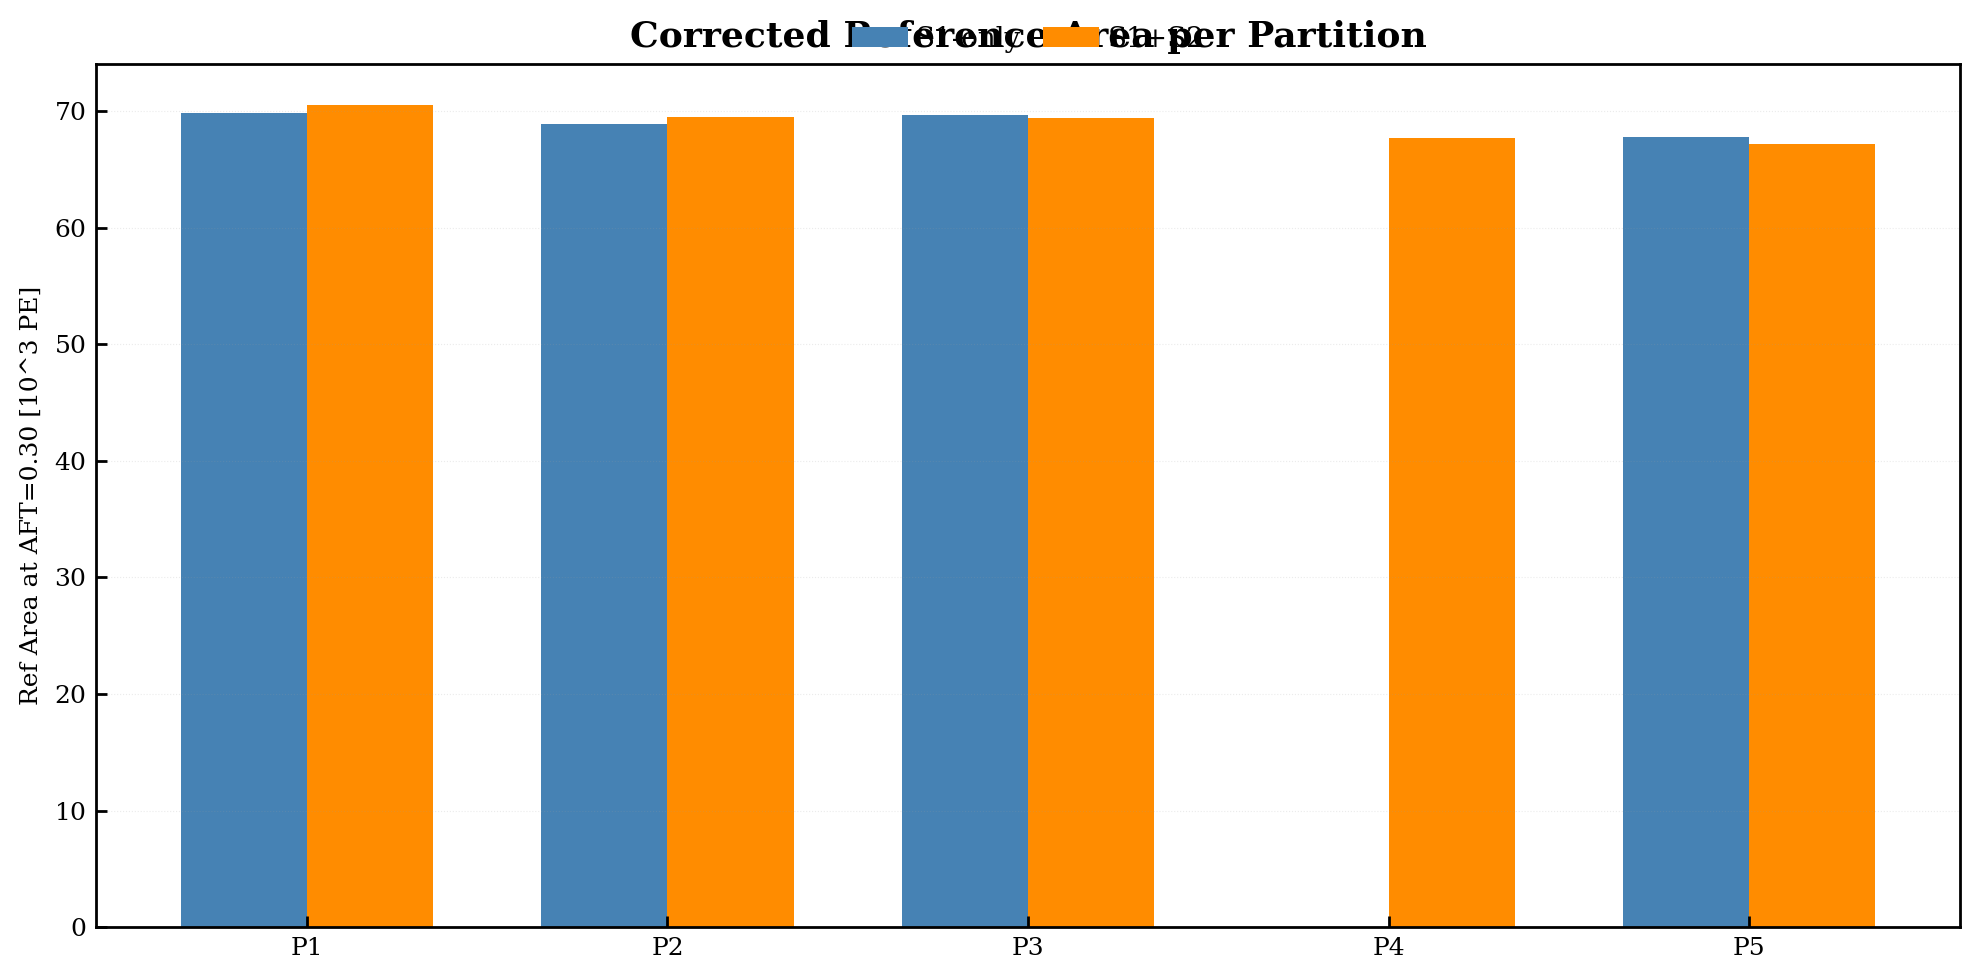


Max spread (S1-only): 2036 PE
Max spread (S1+S2):  3350 PE


In [36]:
# ΔArea at AFT_REF — as function of partition

def ref_area_at_aft(cent_dict):
    """Return AFT-corrected reference area at AFT=0.30 for each partition."""
    vals = {}
    for pname, _, _ in partitions:
        res = cent_dict.get(pname)
        if res and res[0] is not None:
            vals[pname] = exp_bump_model(AFT_REF, *res[0])
    return vals

ref1 = ref_area_at_aft(cent_s1only)
ref2 = ref_area_at_aft(cent_s1s2)

print('Ref area at AFT=%.2f' % AFT_REF)
print()
print('%-35s  %10s  %10s' % ('Partition', 'S1-only', 'S1+S2'))
print('-' * 60)
for pname, _, _ in partitions:
    v1 = ref1.get(pname)
    v2 = ref2.get(pname)
    s1 = '%d PE' % int(v1) if v1 else 'N/A'
    s2 = '%d PE' % int(v2) if v2 else 'N/A'
    print('%-35s  %10s  %10s' % (pname, s1, s2))
print('-' * 60)

# Plot as bar chart
pnames_short = [p[0].split(':')[0].strip() for p in partitions]
v1_list = [ref1.get(p[0]) for p in partitions]
v2_list = [ref2.get(p[0]) for p in partitions]

x = np.arange(len(partitions))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, [v/1e3 if v else 0 for v in v1_list], w, color='steelblue', label='S1-only')
ax.bar(x + w/2, [v/1e3 if v else 0 for v in v2_list], w, color='darkorange', label='S1+S2')
ax.set_xticks(x)
ax.set_xticklabels(pnames_short, fontsize=9)
ax.set_ylabel('Ref Area at AFT=%.2f [10^3 PE]' % AFT_REF)
ax.set_title('Corrected Reference Area per Partition', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2, axis='y')
safe_tight(fig); plt.show()

# Print max spread
def spread(vals):
    v = [x for x in vals if x is not None]
    return max(v) - min(v) if len(v) >= 2 else 0
print('\nMax spread (S1-only): %.0f PE' % spread(v1_list))
print('Max spread (S1+S2):  %.0f PE' % spread(v2_list))

---
## 8. Corrected-Band Diagnosis

Apply per-partition and global AFT corrections, then evaluate offsets on the *corrected* band.
The raw band is too curved to see differences clearly; after correction the band should become
straight (no AFT dependence), making it straightforward to compare peak positions between partitions.

### Correction formula
```
area_corrected = area * exp_bump_model(AFT_ref, p_opt) / exp_bump_model(AFT, p_opt)
```

### Two types of correction
- **Per-partition (PP)**: each partition corrected with its own centerline → `area_corrected_pp`
- **Global**: all partitions corrected with a single global centerline → `area_corrected_global`

If partitions truly have different centerlines, **PP correction** will make each band straight,
while **global correction** will leave residual AFT dependence in individual partitions.


In [37]:
# ═════════════════════════════════════════════════════════
# Fit GLOBAL centerline (two-step, same algorithm as per-partition)
# ═════════════════════════════════════════════════════════

def fit_global_centerline(df, aft_min=0.12, aft_max=0.55, n_bins=50):
    """Two-step global centerline fit (all partitions combined)."""
    d_fit = df[(df["area_fraction_top"] >= aft_min) &
              (df["area_fraction_top"] <= aft_max)].copy()

    # Step 1: manual boundaries
    d_fit["in_band"] = (
        (d_fit["area"] < exp_bump_model(d_fit["area_fraction_top"], *RN_UPPER)) &
        (d_fit["area"] > exp_bump_model(d_fit["area_fraction_top"], *RN_LOWER))
    )
    edges = np.linspace(aft_min, aft_max, n_bins + 1)
    d_fit["aft_bin"] = pd.cut(d_fit["area_fraction_top"], bins=edges)
    medians = d_fit[d_fit["in_band"]].groupby("aft_bin", observed=True)["area"].median()
    aft_c = medians.index.map(lambda iv: iv.mid).astype(float).values
    m_vals = medians.values
    good = ~np.isnan(m_vals)
    p0 = [3.70e4, -8.97e-2, -0.1, -0.05, 35e3]
    p_init, _ = curve_fit(exp_bump_model, aft_c[good], m_vals[good], p0=p0,
                          bounds=([0, -np.inf, -np.inf, -np.inf, 0],
                                  [np.inf, 0, 0, 0, np.inf]), maxfev=10000)

    # Step 2: refine with vertical cut in corrected space
    aft_arr = d_fit["area_fraction_top"].values
    area_arr = d_fit["area"].values
    denom = np.maximum(exp_bump_model(aft_arr, *p_init), 1e3)
    area_corr = area_arr * exp_bump_model(AFT_REF, *p_init) / denom
    mask_band = d_fit["in_band"].values
    mu_rn = np.mean(area_corr[mask_band])
    sig_rn = np.std(area_corr[mask_band])
    d_fit["in_band_refined"] = abs(area_corr - mu_rn) < sig_rn

    medians_ref = d_fit[d_fit["in_band_refined"]].groupby("aft_bin", observed=True)["area"].median()
    aft_c2 = medians_ref.index.map(lambda iv: iv.mid).astype(float).values
    m_vals2 = medians_ref.values
    good2 = ~np.isnan(m_vals2)
    try:
        p_opt, _ = curve_fit(exp_bump_model, aft_c2[good2], m_vals2[good2], p0=p_init,
                              bounds=([0, -np.inf, -np.inf, -np.inf, 0],
                                      [np.inf, 0, 0, 0, np.inf]), maxfev=10000)
    except Exception:
        p_opt = p_init

    return p_opt, mu_rn, sig_rn

print("Fitting global centerline (S1-only)...")
global_opt_s1only, global_mu_s1only, global_sig_s1only = fit_global_centerline(df_s1only)
print("  a=%.0f  e=%.0f  ref_area=%.0f PE  \u03bc_corr=%.0f  \u03c3_corr=%.0f"
      % (global_opt_s1only[0], global_opt_s1only[4],
         exp_bump_model(AFT_REF, *global_opt_s1only),
         global_mu_s1only, global_sig_s1only))

print("Fitting global centerline (S1+S2)...")
global_opt_s1s2, global_mu_s1s2, global_sig_s1s2 = fit_global_centerline(df_s1s2)
print("  a=%.0f  e=%.0f  ref_area=%.0f PE  \u03bc_corr=%.0f  \u03c3_corr=%.0f"
      % (global_opt_s1s2[0], global_opt_s1s2[4],
         exp_bump_model(AFT_REF, *global_opt_s1s2),
         global_mu_s1s2, global_sig_s1s2))

# ═════════════════════════════════════════════════════════
# Apply AFT Corrections
# ═════════════════════════════════════════════════════════
# Formula: area_corrected = area * model(AFT_ref, p_opt) / model(AFT, p_opt)
# Same as original analysis notebook Correction 1b.

# ── S1-only: per-partition correction ──
aft_s1 = df_s1only["area_fraction_top"].values
area_s1 = df_s1only["area"].values
df_s1only["area_corrected_pp"] = np.nan
for pname, _, _ in partitions:
    res = cent_s1only.get(pname)
    if res and res[0] is not None:
        mask = (df_s1only["partition"] == pname).values
        denom = np.maximum(exp_bump_model(aft_s1[mask], *res[0]), 1e3)
        df_s1only.loc[mask, "area_corrected_pp"] = (
            area_s1[mask] * exp_bump_model(AFT_REF, *res[0]) / denom)

# ── S1-only: global correction ──
denom_global_s1 = np.maximum(exp_bump_model(aft_s1, *global_opt_s1only), 1e3)
df_s1only["area_corrected_global"] = area_s1 * exp_bump_model(AFT_REF, *global_opt_s1only) / denom_global_s1

# ── S1+S2: per-partition correction ──
aft_s2 = df_s1s2["area_fraction_top"].values
area_s2 = df_s1s2["area"].values
df_s1s2["area_corrected_pp"] = np.nan
for pname, _, _ in partitions:
    res = cent_s1s2.get(pname)
    if res and res[0] is not None:
        mask = (df_s1s2["partition"] == pname).values
        denom = np.maximum(exp_bump_model(aft_s2[mask], *res[0]), 1e3)
        df_s1s2.loc[mask, "area_corrected_pp"] = (
            area_s2[mask] * exp_bump_model(AFT_REF, *res[0]) / denom)

# ── S1+S2: global correction ──
denom_global_s2 = np.maximum(exp_bump_model(aft_s2, *global_opt_s1s2), 1e3)
df_s1s2["area_corrected_global"] = area_s2 * exp_bump_model(AFT_REF, *global_opt_s1s2) / denom_global_s2

print("\nCorrections applied.")
print("  S1-only: %d events (PP), %d events (Global)"
      % (df_s1only["area_corrected_pp"].notna().sum(),
         df_s1only["area_corrected_global"].notna().sum()))
print("  S1+S2:   %d events (PP), %d events (Global)"
      % (df_s1s2["area_corrected_pp"].notna().sum(),
         df_s1s2["area_corrected_global"].notna().sum()))


Fitting global centerline (S1-only)...
  a=46106  e=62103  ref_area=68438 PE  μ_corr=68566  σ_corr=2576
Fitting global centerline (S1+S2)...
  a=434640  e=62608  ref_area=68306 PE  μ_corr=68357  σ_corr=2655

Corrections applied.
  S1-only: 2098021 events (PP), 2264866 events (Global)
  S1+S2:   29336185 events (PP), 32780402 events (Global)


### Per-partition corrected band (2-panel: Raw -> Corrected)

For each partition, two panels side by side (following the original Correction 1a style):

| Panel | Content |
|-------|---------|
| **Left** | Raw area vs AFT 2D histogram + fitted per-partition centerline (yellow curve) |
| **Right** | `area_corrected_pp` vs AFT — band should become **straight (vertical)** after correction |

Right panel annotations:
- **Yellow solid**: partition median `area_corrected_pp` (computed within vertical band)
- **Cyan dashed**: +-2sigma vertical band boundaries
- **Magenta dotted**: global median `area_corrected_global` (for comparison)
- **Orange dots**: median `area_corrected_pp` per AFT bin (within band) — checks residual AFT dependence

Band finding: iterative core selection (median/std -> +-1.5sigma core -> mean/std of core -> +-2sigma band).
If per-partition != global, the yellow and magenta lines will be offset.


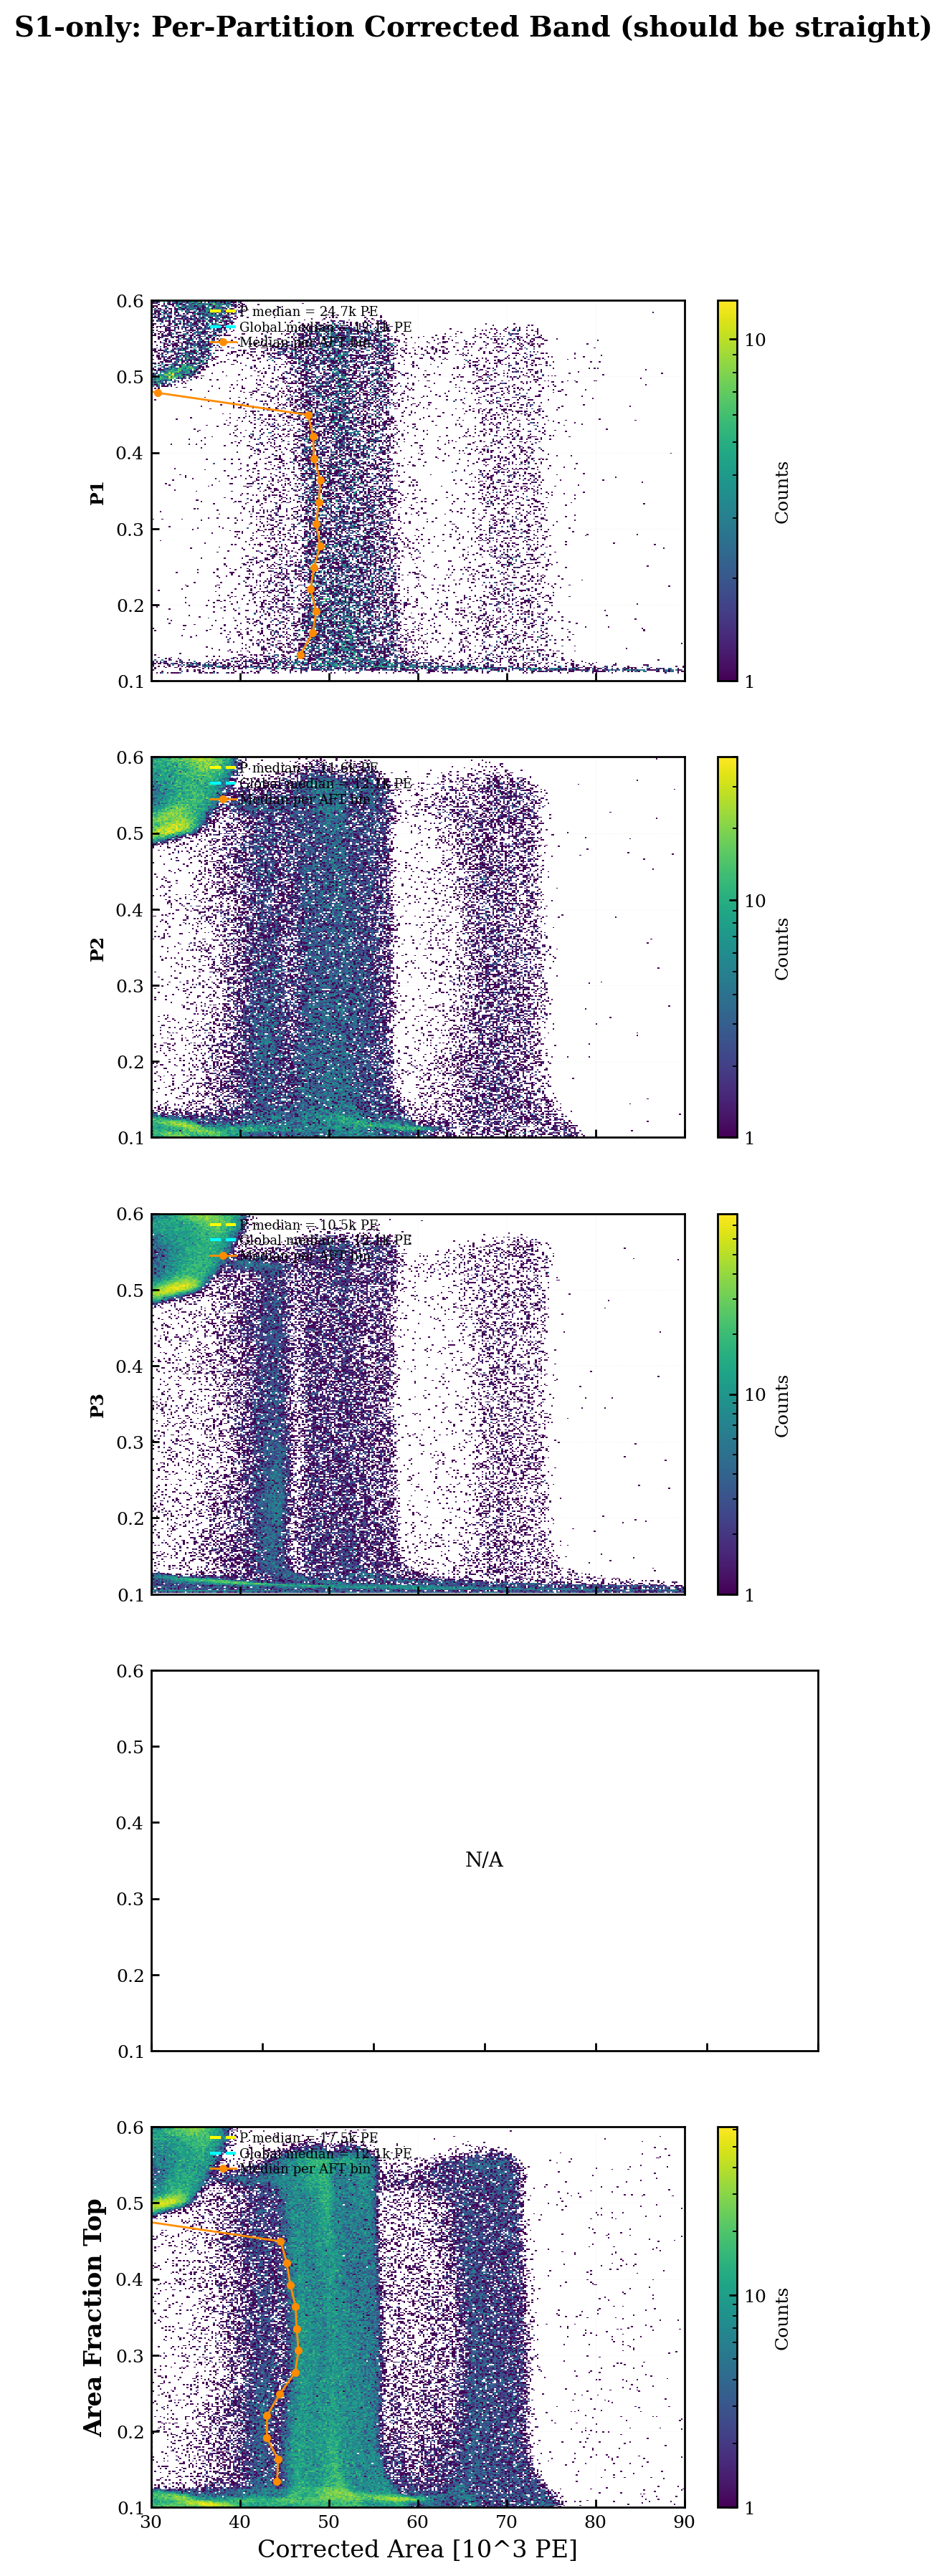

In [38]:
# S1-only: per-partition corrected band (following original Correction 1a style)
# Left: raw area vs AFT with refined centerline from this partition.
# Right: area_corrected_pp vs AFT - should be vertical if correction works.

aft_fine = np.linspace(0.10, 0.60, 500)
aft_bins_inner = np.linspace(AFT_FIT_MIN, AFT_FIT_MAX, 16)
N_SIGMA = 2.0

for idx, (pname, t0, t1) in enumerate(partitions):
    res = cent_s1only.get(pname)
    if not res or res[0] is None:
        continue
    p_opt, d_fit = res
    d = df_s1only[df_s1only["partition"] == pname]
    d_aft = d[(d["area_fraction_top"] >= AFT_FIT_MIN) & (d["area_fraction_top"] <= AFT_FIT_MAX)]

    # Find vertical Rn band: iterative core selection (equiv. two-step fit Step 2)
    pp_vals = d_aft["area_corrected_pp"].values
    mu0, sig0 = np.median(pp_vals), np.std(pp_vals)
    in_core = (pp_vals >= mu0 - 1.5*sig0) & (pp_vals <= mu0 + 1.5*sig0)
    mu_rn = pp_vals[in_core].mean()
    sig_rn = pp_vals[in_core].std()

    rn_band_lo = mu_rn - N_SIGMA * sig_rn
    rn_band_hi = mu_rn + N_SIGMA * sig_rn
    in_band = (pp_vals >= rn_band_lo) & (pp_vals <= rn_band_hi)
    d_band = d_aft[in_band]
    pp_mu = d_band["area_corrected_pp"].median()

    print("%s: in-band events = %d, mu=%.0f sigma=%.0f PE, +-%.0fsigma band = [%.0f, %.0f] PE"
          % (pname.split(":")[0], len(d_band), mu_rn, sig_rn, N_SIGMA, rn_band_lo, rn_band_hi))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # LEFT: Raw Area vs AFT + centerline
    h = ax1.hist2d(d_aft["area"], d_aft["area_fraction_top"],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap="viridis")
    plt.colorbar(h[3], ax=ax1, label="Counts")
    ax1.plot(exp_bump_model(aft_fine, *p_opt), aft_fine,
             "-", color="yellow", lw=2, label="Per-partition CL")
    ax1.set_xlabel("Area [PE]", fontsize=12)
    ax1.set_ylabel("Area Fraction Top", fontsize=12)
    ax1.set_title("Raw: Area vs AFT", fontsize=13)
    ax1.legend(fontsize=9, loc="lower right")
    ax1.grid(True, alpha=0.2)

    # RIGHT: Corrected Area vs AFT with vertical band
    h = ax2.hist2d(d_aft["area_corrected_pp"], d_aft["area_fraction_top"],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap="viridis")
    plt.colorbar(h[3], ax=ax2, label="Counts")
    ax2.axvline(x=pp_mu, color="yellow", lw=2, alpha=0.7,
                label="P median = %.0f PE" % pp_mu)
    ax2.axvline(x=rn_band_lo, color="cyan", ls="--", lw=1.5,
                label="+-%.0fsigma band = [%.0f, %.0f] PE" % (N_SIGMA, rn_band_lo, rn_band_hi))
    ax2.axvline(x=rn_band_hi, color="cyan", ls="--", lw=1.5)
    global_med = df_s1only.loc[
        (df_s1only["area_fraction_top"] >= AFT_FIT_MIN) & (df_s1only["area_fraction_top"] <= AFT_FIT_MAX),
        "area_corrected_global"].median()
    ax2.axvline(x=global_med, color="magenta", ls=":", lw=1.5,
                label="Global median = %.0f PE" % global_med)
    d_bin = d_band.copy()
    d_bin["aft_bin"] = pd.cut(d_bin["area_fraction_top"], bins=aft_bins_inner)
    meds = d_bin.groupby("aft_bin", observed=True)["area_corrected_pp"].median()
    aft_mids = meds.index.map(lambda iv: iv.mid).astype(float).values
    ax2.plot(meds.values, aft_mids, "o-", color="darkorange", lw=1, ms=3,
             label="Median per AFT bin")
    ax2.set_xlabel("AFT-Corrected Area [PE]", fontsize=12)
    ax2.set_ylabel("Area Fraction Top", fontsize=12)
    ax2.set_title("Corrected: area_pp vs AFT (should be vertical)", fontsize=13)
    ax2.legend(fontsize=8, loc="lower right", ncol=1, framealpha=0.85)
    ax2.grid(True, alpha=0.2)

    pshort = pname.split(":")[0]
    fig.suptitle("S1-only %s: Raw -> Corrected band" % pshort, fontsize=14, fontweight="bold")
    safe_tight(fig)
    plt.show()


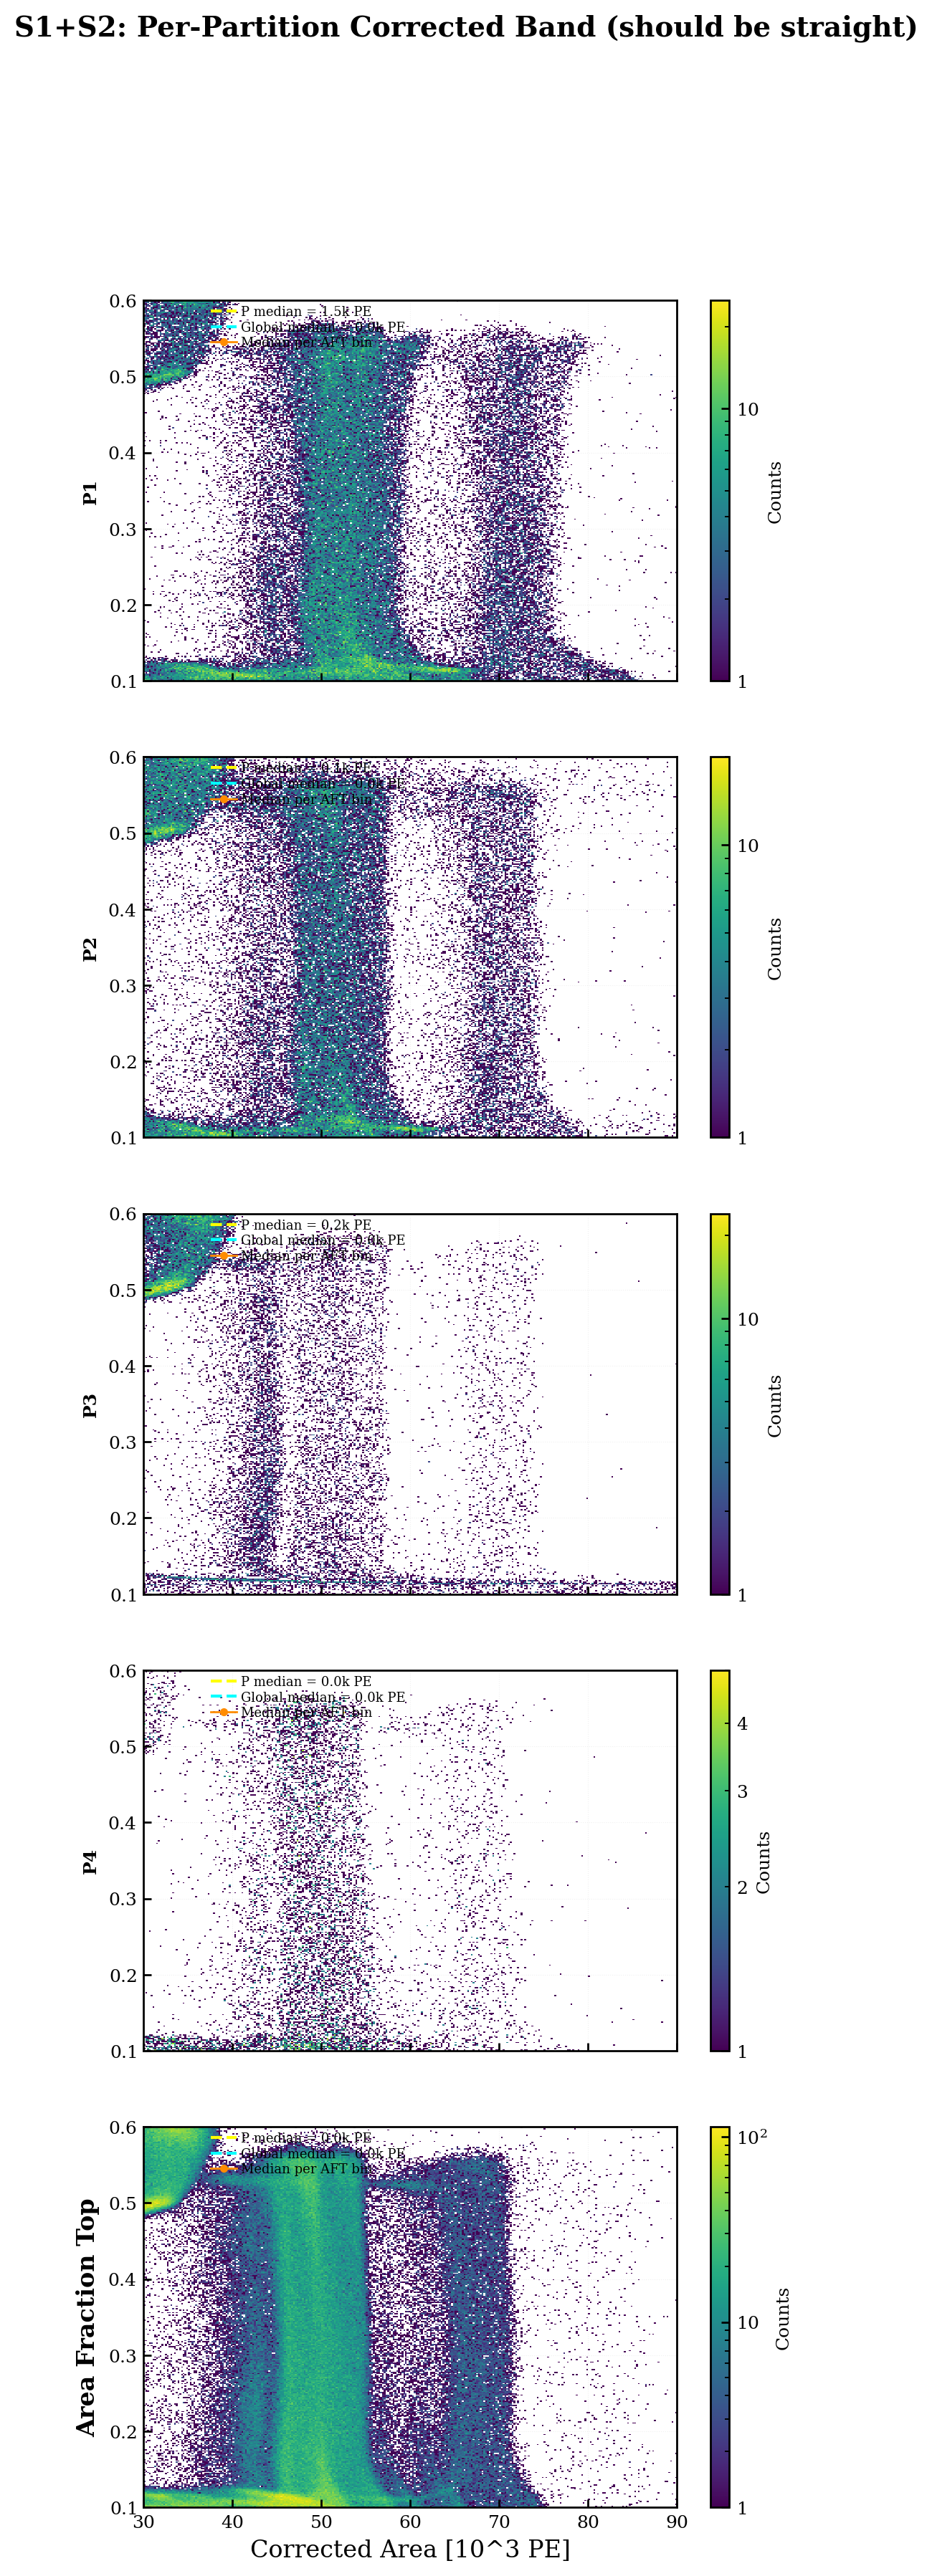

In [39]:
# S1+S2: per-partition corrected band (same layout as S1-only above)

for idx, (pname, t0, t1) in enumerate(partitions):
    res = cent_s1s2.get(pname)
    if not res or res[0] is None:
        continue
    p_opt, d_fit = res
    d = df_s1s2[df_s1s2["partition"] == pname]
    d_aft = d[(d["area_fraction_top"] >= AFT_FIT_MIN) & (d["area_fraction_top"] <= AFT_FIT_MAX)]

    pp_vals = d_aft["area_corrected_pp"].values
    mu0, sig0 = np.median(pp_vals), np.std(pp_vals)
    in_core = (pp_vals >= mu0 - 1.5*sig0) & (pp_vals <= mu0 + 1.5*sig0)
    mu_rn = pp_vals[in_core].mean()
    sig_rn = pp_vals[in_core].std()

    rn_band_lo = mu_rn - N_SIGMA * sig_rn
    rn_band_hi = mu_rn + N_SIGMA * sig_rn
    in_band = (pp_vals >= rn_band_lo) & (pp_vals <= rn_band_hi)
    d_band = d_aft[in_band]
    pp_mu = d_band["area_corrected_pp"].median()

    print("%s: in-band events = %d, mu=%.0f sigma=%.0f PE, +-%.0fsigma band = [%.0f, %.0f] PE"
          % (pname.split(":")[0], len(d_band), mu_rn, sig_rn, N_SIGMA, rn_band_lo, rn_band_hi))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # LEFT: Raw
    h = ax1.hist2d(d_aft["area"], d_aft["area_fraction_top"],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap="viridis")
    plt.colorbar(h[3], ax=ax1, label="Counts")
    ax1.plot(exp_bump_model(aft_fine, *p_opt), aft_fine,
             "-", color="yellow", lw=2, label="Per-partition CL")
    ax1.set_xlabel("Area [PE]", fontsize=12)
    ax1.set_ylabel("Area Fraction Top", fontsize=12)
    ax1.set_title("Raw: Area vs AFT", fontsize=13)
    ax1.legend(fontsize=9, loc="lower right")
    ax1.grid(True, alpha=0.2)

    # RIGHT: Corrected
    h = ax2.hist2d(d_aft["area_corrected_pp"], d_aft["area_fraction_top"],
                   bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
                   cmin=1, norm=matplotlib.colors.LogNorm(), cmap="viridis")
    plt.colorbar(h[3], ax=ax2, label="Counts")
    ax2.axvline(x=pp_mu, color="yellow", lw=2, alpha=0.7,
                label="P median = %.0f PE" % pp_mu)
    ax2.axvline(x=rn_band_lo, color="cyan", ls="--", lw=1.5,
                label="+-%.0fsigma band = [%.0f, %.0f] PE" % (N_SIGMA, rn_band_lo, rn_band_hi))
    ax2.axvline(x=rn_band_hi, color="cyan", ls="--", lw=1.5)
    global_med = df_s1s2.loc[
        (df_s1s2["area_fraction_top"] >= AFT_FIT_MIN) & (df_s1s2["area_fraction_top"] <= AFT_FIT_MAX),
        "area_corrected_global"].median()
    ax2.axvline(x=global_med, color="magenta", ls=":", lw=1.5,
                label="Global median = %.0f PE" % global_med)
    d_bin = d_band.copy()
    d_bin["aft_bin"] = pd.cut(d_bin["area_fraction_top"], bins=aft_bins_inner)
    meds = d_bin.groupby("aft_bin", observed=True)["area_corrected_pp"].median()
    aft_mids = meds.index.map(lambda iv: iv.mid).astype(float).values
    ax2.plot(meds.values, aft_mids, "o-", color="darkorange", lw=1, ms=3,
             label="Median per AFT bin")
    ax2.set_xlabel("AFT-Corrected Area [PE]", fontsize=12)
    ax2.set_ylabel("Area Fraction Top", fontsize=12)
    ax2.set_title("Corrected: area_pp vs AFT (should be vertical)", fontsize=13)
    ax2.legend(fontsize=8, loc="lower right", ncol=1, framealpha=0.85)
    ax2.grid(True, alpha=0.2)

    pshort = pname.split(":")[0]
    fig.suptitle("S1+S2 %s: Raw -> Corrected band" % pshort, fontsize=14, fontweight="bold")
    safe_tight(fig)
    plt.show()


### Per-partition internal residuals

Check if the per-partition correction fully removes AFT dependence **within** each partition.
For each partition, bin the corrected band by AFT and compute the median `area_corrected_pp`
minus the partition's overall median. If the correction is successful, residuals scatter
around zero with no systematic trend vs AFT.


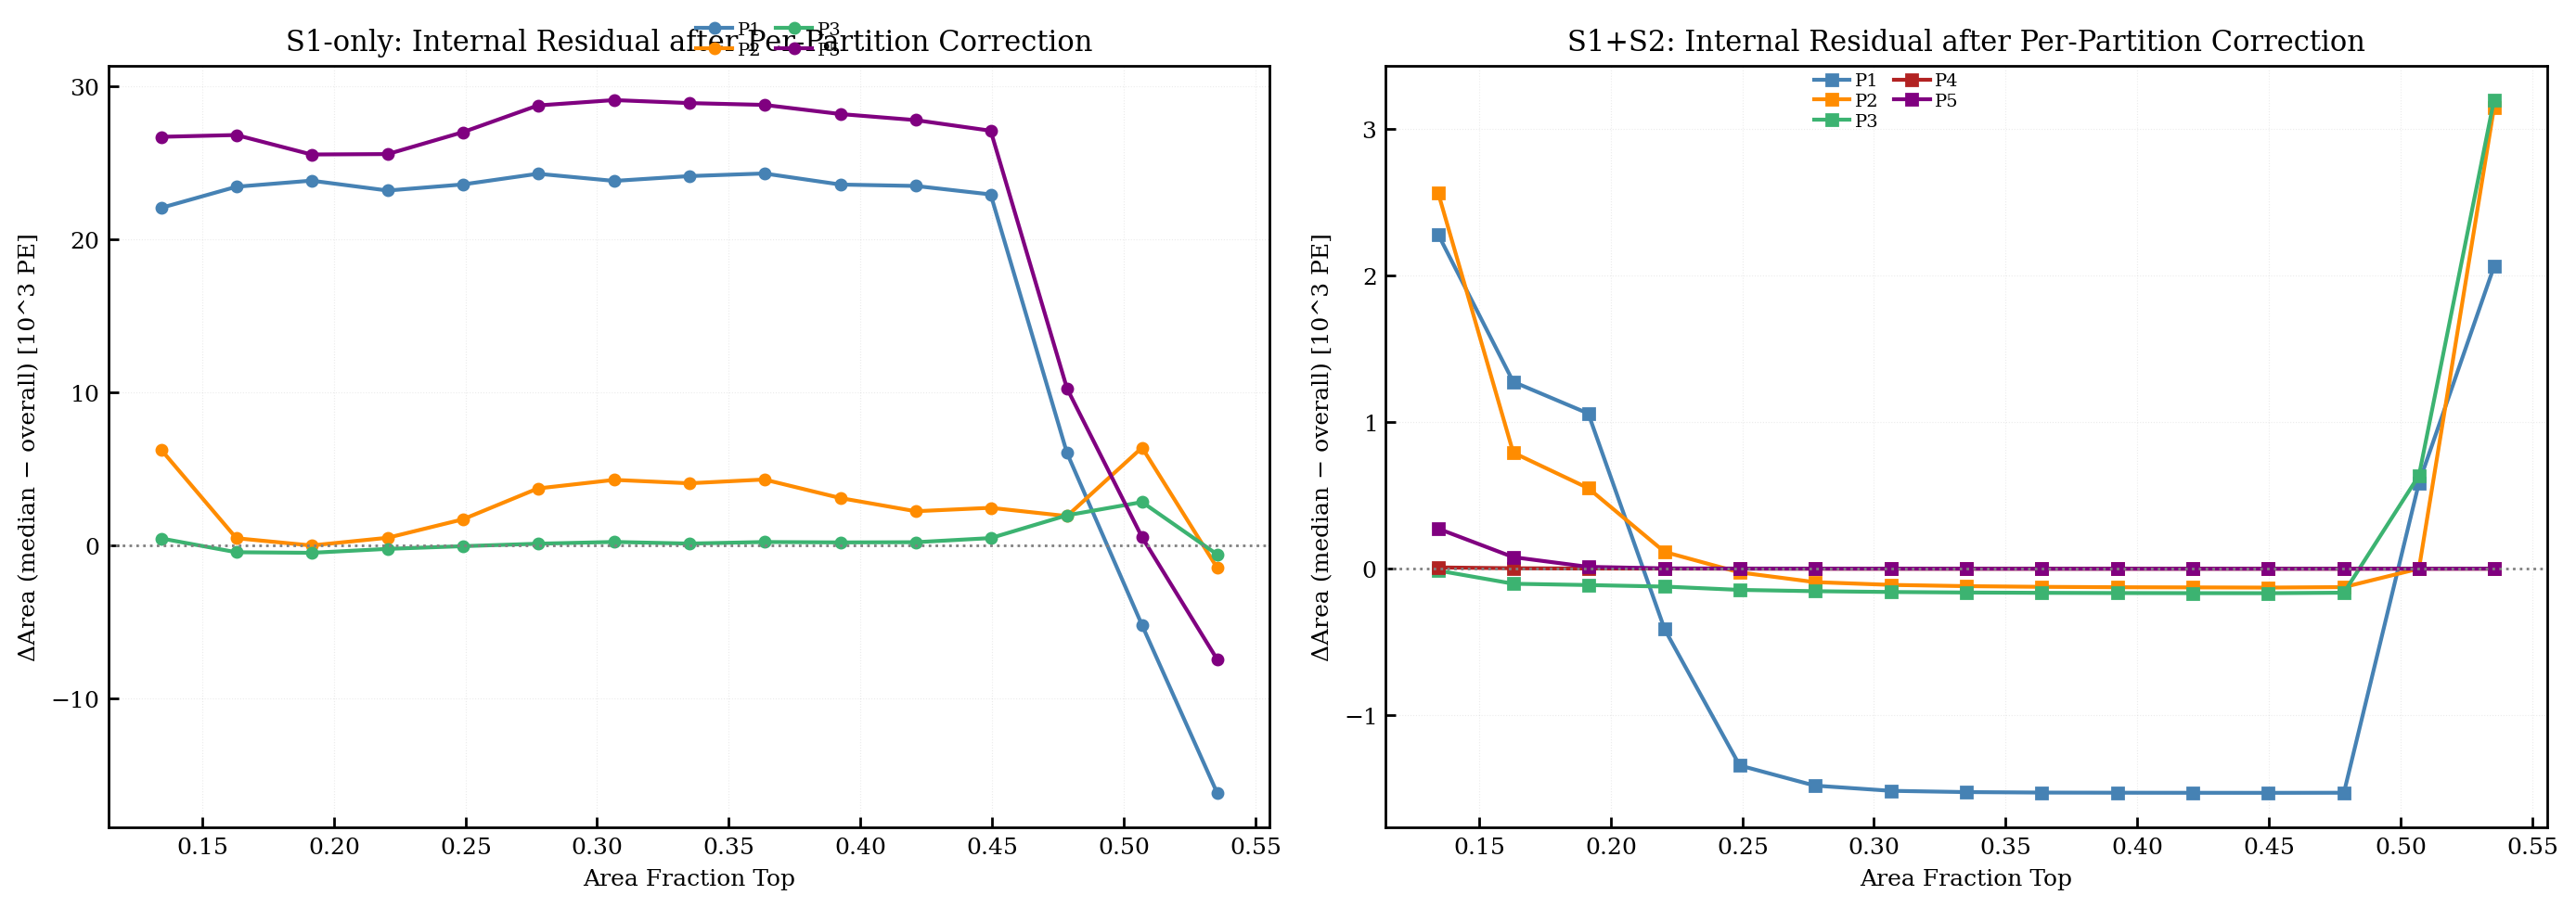

In [40]:
# Per-partition internal residuals: how flat is the band after per-partition correction?
# For each partition, bin by AFT, compute median corrected area, show deviation from partition mean.

def compute_aft_residuals(df, pname, col="area_corrected_pp", n_bins=15):
    """Return arrays: aft_mid, delta_area (median - overall mean) per AFT bin."""
    d = df[df["partition"] == pname].copy()
    d = d[(d["area_fraction_top"] >= AFT_FIT_MIN) & (d["area_fraction_top"] <= AFT_FIT_MAX)]
    if len(d) < 50:
        return None, None
    edges = np.linspace(AFT_FIT_MIN, AFT_FIT_MAX, n_bins + 1)
    d["aft_bin"] = pd.cut(d["area_fraction_top"], bins=edges)
    medians = d.groupby("aft_bin", observed=True)[col].median()
    aft_mid = medians.index.map(lambda iv: iv.mid).astype(float).values
    overall_median = d[col].median()
    return aft_mid, medians.values - overall_median

pcolors = ["steelblue", "darkorange", "mediumseagreen", "firebrick", "purple"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for idx, (pname, _, _) in enumerate(partitions):
    af, dv = compute_aft_residuals(df_s1only, pname)
    if af is not None:
        ax1.plot(af, dv / 1e3, "o-", color=pcolors[idx], lw=1.5, ms=4, label=pname.split(":")[0])
    af, dv = compute_aft_residuals(df_s1s2, pname)
    if af is not None:
        ax2.plot(af, dv / 1e3, "s-", color=pcolors[idx], lw=1.5, ms=4, label=pname.split(":")[0])

for ax, title in zip([ax1, ax2], ["S1-only", "S1+S2"]):
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set_xlabel("Area Fraction Top")
    ax.set_ylabel("ΔArea (median − overall) [10^3 PE]")
    ax.set_title(f"{title}: Internal Residual after Per-Partition Correction", fontsize=11)
    ax.legend(fontsize=7, loc="best", ncol=2)
    ax.grid(True, alpha=0.2)

safe_tight(fig); plt.show()


### Partition-vs-global offset

Apply the **global** centerline to each partition and measure the residual offset.
ΔArea = median(`area_corrected_global`) − median(`area_corrected_pp`) per AFT bin.
If partitions truly have different centerlines, these residuals will show systematic
offsets (non-zero and/or AFT-dependent). This quantifies the error introduced by using
a single global correction for all partitions.


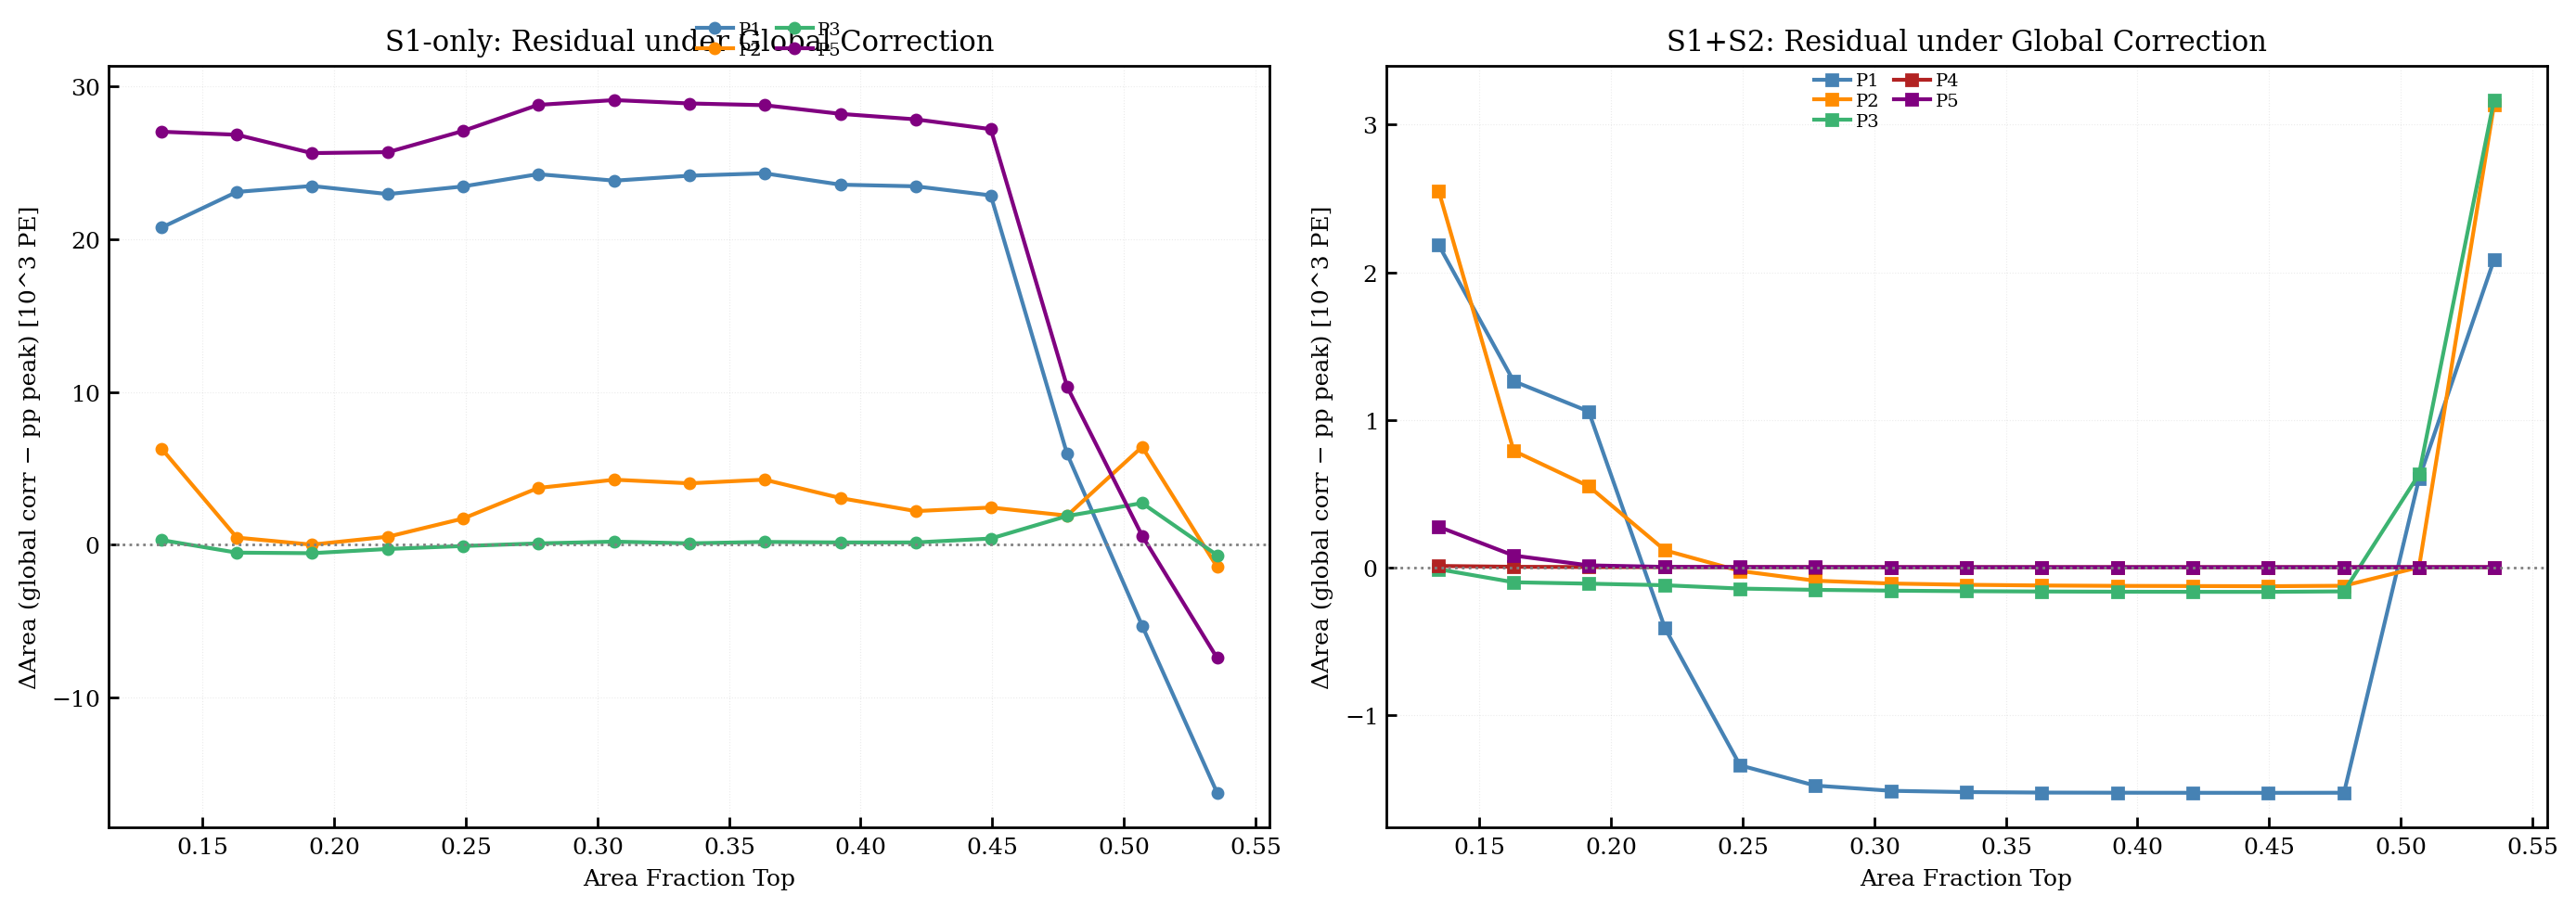

In [41]:
# Partition vs Global offset: use GLOBAL correction, then compare per-partition corrected peaks.
# If partitions differ, the globally-corrected band will show residual AFT dependence per partition.

def compute_global_residuals(df, pname, col="area_corrected_global", col_pp="area_corrected_pp", n_bins=15):
    """For a single partition under global correction, compute residuals vs AFT."""
    d = df[df["partition"] == pname].copy()
    d = d[(d["area_fraction_top"] >= AFT_FIT_MIN) & (d["area_fraction_top"] <= AFT_FIT_MAX)]
    if len(d) < 50:
        return None, None, None
    edges = np.linspace(AFT_FIT_MIN, AFT_FIT_MAX, n_bins + 1)
    d["aft_bin"] = pd.cut(d["area_fraction_top"], bins=edges)
    medians_global = d.groupby("aft_bin", observed=True)[col].median()
    aft_mid = medians_global.index.map(lambda iv: iv.mid).astype(float).values
    overall_pp = d[col_pp].median()  # reference: per-partition corrected peak
    return aft_mid, medians_global.values - overall_pp, overall_pp

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for idx, (pname, _, _) in enumerate(partitions):
    af, dv, _ = compute_global_residuals(df_s1only, pname)
    if af is not None:
        ax1.plot(af, dv / 1e3, "o-", color=pcolors[idx], lw=1.5, ms=4, label=pname.split(":")[0])
    af, dv, _ = compute_global_residuals(df_s1s2, pname)
    if af is not None:
        ax2.plot(af, dv / 1e3, "s-", color=pcolors[idx], lw=1.5, ms=4, label=pname.split(":")[0])

for ax, title in zip([ax1, ax2], ["S1-only", "S1+S2"]):
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set_xlabel("Area Fraction Top")
    ax.set_ylabel("ΔArea (global corr − pp peak) [10^3 PE]")
    ax.set_title(f"{title}: Residual under Global Correction", fontsize=11)
    ax.legend(fontsize=7, loc="best", ncol=2)
    ax.grid(True, alpha=0.2)

safe_tight(fig); plt.show()


### Summary: per-partition vs global peak positions

Bar chart comparing the corrected peak area for each partition under per-partition vs
global correction. The spread of peaks quantifies how much the centerline shifts across
partitions. A large spread (> 300-500 PE) indicates per-partition correction is necessary.


Partition                             S1-only PP   S1-only Gl     S1+S2 PP     S1+S2 Gl
-------------------------------------------------------------------------------------
P1: Q5 (May 1–11)                          24745        24643         1533         1539
P2: ST707 (May 11–25)                      11577        11598          134          133
P3: NO purifier (May 25–Jun5)              10512        10451          171          170
P4: Dist. on (Jun 5–20)                      N/A          N/A            2            2
P5: LXe lvl Δ (Jun 20–Jul2)                17471        17520            2            2
-------------------------------------------------------------------------------------


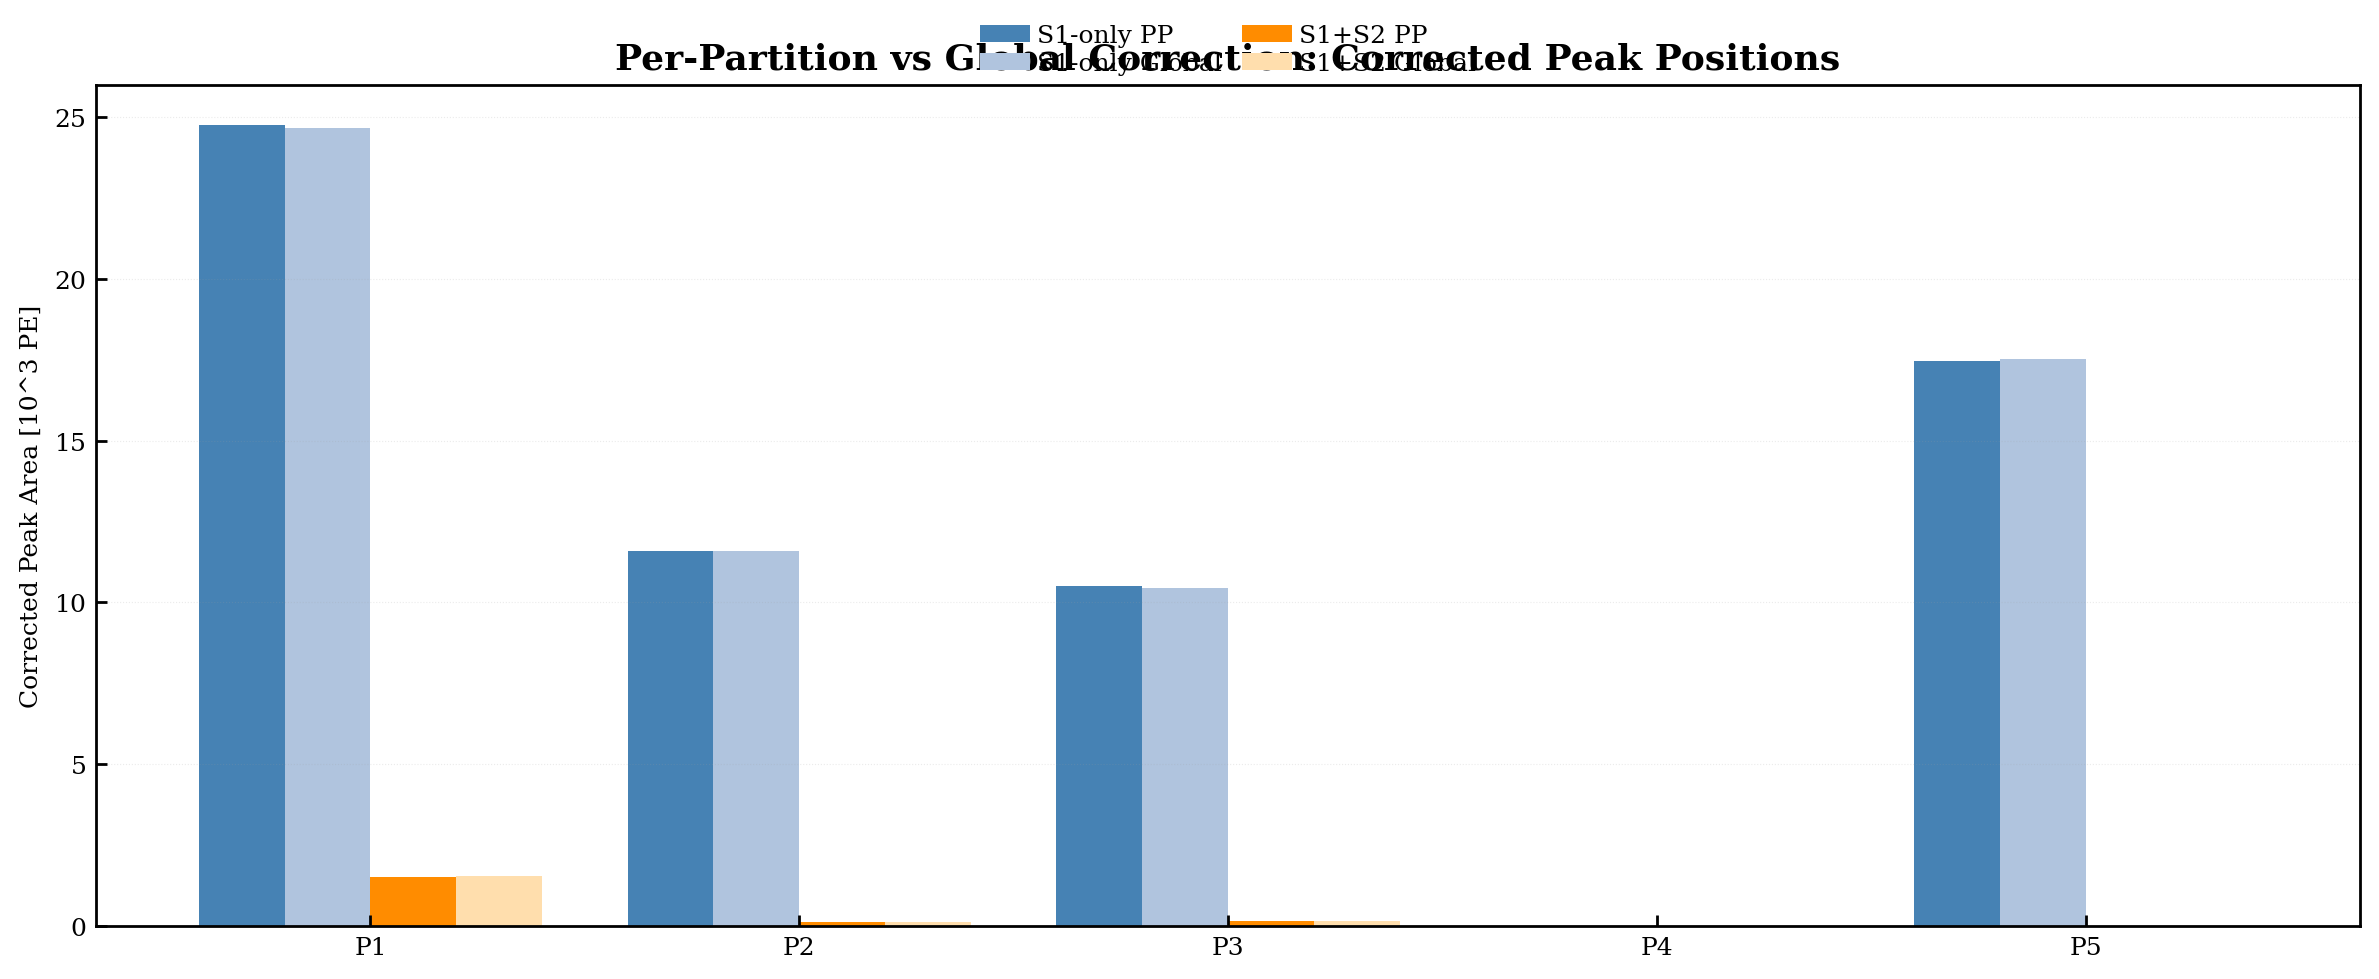

S1-only PP spread: 14233 PE
S1+S2 PP spread: 1531 PE
S1-only Global spread: 14192 PE
S1+S2 Global spread: 1537 PE
Median |PP - Global| offset (S1-only): 55 PE
Median |PP - Global| offset (S1+S2):  0 PE


In [42]:
# Summary: compare per-partition vs global correction peaks

pp_peaks_s1only = []
pp_peaks_s1s2 = []
global_peaks_s1only = []
global_peaks_s1s2 = []

for pname, _, _ in partitions:
    for df, pp_list, gl_list, pp_col, gl_col in [
        (df_s1only, pp_peaks_s1only, global_peaks_s1only, "area_corrected_pp", "area_corrected_global"),
        (df_s1s2, pp_peaks_s1s2, global_peaks_s1s2, "area_corrected_pp", "area_corrected_global"),
    ]:
        d = df[(df["partition"] == pname) & (df["area_fraction_top"] >= AFT_FIT_MIN) & (df["area_fraction_top"] <= AFT_FIT_MAX)]
        if pp_col in d.columns and len(d) > 10:
            pp_list.append(d[pp_col].median())
            gl_list.append(d[gl_col].median())
        else:
            pp_list.append(np.nan)
            gl_list.append(np.nan)

print("%-35s %12s %12s %12s %12s" % ("Partition", "S1-only PP", "S1-only Gl", "S1+S2 PP", "S1+S2 Gl"))
print("-" * 85)
for i, (pname, _, _) in enumerate(partitions):
    vals = [pp_peaks_s1only[i], global_peaks_s1only[i], pp_peaks_s1s2[i], global_peaks_s1s2[i]]
    strs = [("%d" % int(v)) if not np.isnan(v) else "N/A" for v in vals]
    print("%-35s %12s %12s %12s %12s" % (pname, strs[0], strs[1], strs[2], strs[3]))
print("-" * 85)

# Bar chart
pnames_short = [p[0].split(":")[0].strip() for p in partitions]
x = np.arange(len(partitions))
w = 0.2
fig, ax = plt.subplots(figsize=(12, 5))
all_vals = [pp_peaks_s1only, global_peaks_s1only, pp_peaks_s1s2, global_peaks_s1s2]
labels = ["S1-only PP", "S1-only Global", "S1+S2 PP", "S1+S2 Global"]
colors = ["steelblue", "lightsteelblue", "darkorange", "navajowhite"]
offsets = [-1.5, -0.5, 0.5, 1.5]
for vals_i, label, color, off in zip(all_vals, labels, colors, offsets):
    y = [v / 1e3 if not np.isnan(v) else 0 for v in vals_i]
    ax.bar(x + off * w, y, w, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels(pnames_short, fontsize=9)
ax.set_ylabel("Corrected Peak Area [10^3 PE]")
ax.set_title("Per-Partition vs Global Correction: Corrected Peak Positions", fontsize=13, fontweight="bold")
ax.legend(fontsize=9, ncol=2)
ax.grid(True, alpha=0.2, axis="y")
safe_tight(fig); plt.show()

# Print spreads
for vals, name in [(pp_peaks_s1only, "S1-only PP"), (pp_peaks_s1s2, "S1+S2 PP"),
                     (global_peaks_s1only, "S1-only Global"), (global_peaks_s1s2, "S1+S2 Global")]:
    vv = [v for v in vals if not np.isnan(v)]
    if len(vv) >= 2:
        print("%s spread: %.0f PE" % (name, max(vv) - min(vv)))

# Per-dataset offset (median of differences)
diffs_s1only = [abs(pp_peaks_s1only[i] - global_peaks_s1only[i]) for i in range(len(partitions)) if not np.isnan(pp_peaks_s1only[i])]
diffs_s1s2 = [abs(pp_peaks_s1s2[i] - global_peaks_s1s2[i]) for i in range(len(partitions)) if not np.isnan(pp_peaks_s1s2[i])]
if diffs_s1only:
    print("Median |PP - Global| offset (S1-only): %.0f PE" % np.median(diffs_s1only))
if diffs_s1s2:
    print("Median |PP - Global| offset (S1+S2):  %.0f PE" % np.median(diffs_s1s2))
